# Phase 5 : EDA Analytique

## Objectif

Cette phase vise à analyser le dataset NBA enrichi afin de répondre aux
questions business définies lors du cadrage et de préparer les hypothèses
qui seront vérifiées lors de la modélisation.

La cible du projet est `pts_next_season`, correspondant aux points par match
d'un joueur lors de la saison immédiatement suivante.

Contrairement à l'EDA diagnostique, l'objectif n'est plus de rechercher des
problèmes de qualité mais de produire des résultats quantifiés, des insights
interprétables et des recommandations.

## Questions business analysées

1. Quels joueurs progressent ou régressent le plus offensivement d'une saison
   à la suivante ?

2. Comment l'âge et l'expérience sont-ils associés à l'évolution des points
   en saison N+1 ?

3. Dans quelle mesure le rôle offensif du joueur en saison N, notamment son
   temps de jeu, son volume de tirs et son usage, est-il associé à sa
   production en saison N+1 ?

4. Dans quelle mesure le contexte collectif de l'équipe en saison N est-il
   associé à la production offensive du joueur en saison N+1 ?

5. Le poste du joueur est-il associé à son profil offensif et à sa production
   en saison N+1 ?

In [224]:
from pathlib import Path

import numpy as np
import pandas as pd


pd.set_option(
    "display.max_columns",
    100
)

pd.set_option(
    "display.max_rows",
    50
)


PROJECT_ROOT = Path.cwd()


PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "phase5_eda"
)


REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [225]:
# Chargement des données

final_dataset = pd.read_parquet(
    PROCESSED_DIR
    / "nba_player_season_enriched.parquet"
)


supervised_dataset = pd.read_parquet(
    PROCESSED_DIR
    / "nba_player_season_supervised.parquet"
)


print(
    "Dataset complet :",
    final_dataset.shape
)

print(
    "Dataset supervisé :",
    supervised_dataset.shape
)

print(
    "Période :",
    final_dataset["SEASON"].min(),
    "à",
    final_dataset["SEASON"].max()
)

print(
    "Cible disponible :",
    supervised_dataset[
        "pts_next_season"
    ].notna().sum()
)

Dataset complet : (12846, 251)
Dataset supervisé : (9911, 251)
Période : 1996-97 à 2022-23
Cible disponible : 9911


## Analyse générale de la cible

Avant de répondre aux questions business, la distribution de
`pts_next_season` est étudiée afin de comprendre l'ordre de grandeur,
la dispersion et les valeurs extrêmes de la variable à prédire.

Cette analyse servira de référence pour interpréter les résultats suivants.

In [226]:
# Statistiques descriptives de la cible

target = supervised_dataset[
    "pts_next_season"
]


target_stats = target.describe(
    percentiles=[
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
    ]
)


display(
    target_stats.to_frame(
        name="pts_next_season"
    )
)

,pts_next_season
count,9911.000000
mean,9.097457
std,6.140855
min,0.000000
10%,2.300000
25%,4.400000
50%,7.700000
75%,12.600000
90%,18.000000
95%,21.150000


In [227]:
# Segmentation de la cible

target_segments = pd.cut(
    target,
    bins=[
        -np.inf,
        5,
        10,
        15,
        20,
        np.inf,
    ],
    labels=[
        "< 5 PTS",
        "5-10 PTS",
        "10-15 PTS",
        "15-20 PTS",
        "20+ PTS",
    ],
    right=False,
)


target_distribution = (
    target_segments
    .value_counts()
    .sort_index()
    .rename_axis(
        "segment"
    )
    .reset_index(
        name="joueur_saisons"
    )
)


target_distribution[
    "pourcentage"
] = (
    target_distribution[
        "joueur_saisons"
    ]
    / len(target)
    * 100
).round(2)


display(
    target_distribution
)

,segment,joueur_saisons,pourcentage
0,< 5 PTS,2937,29.63
1,5-10 PTS,3318,33.48
2,10-15 PTS,1962,19.80
3,15-20 PTS,1021,10.30
4,20+ PTS,673,6.79


## Question Business 1 : progression et régression offensive

### Reformulation

**Question précise :**  
Quels joueurs progressent ou régressent le plus en termes de points par match
entre la saison N et la saison N+1 ?

**Métriques utilisées :**
- points par match en saison N ;
- points par match en saison N+1 ;
- variation absolue entre N et N+1 ;
- proportion de joueurs en progression, stables ou en régression.

**Granularité :**  
une ligne par joueur-saison disposant d'une saison N+1 consécutive.

La variable `PTS_NEXT_CHANGE` utilisée dans cette analyse est uniquement une
variable analytique. Elle ne sera pas utilisée comme feature du futur modèle.

In [228]:
# Préparation de l'analyse

eda_dataset = supervised_dataset.copy()


eda_dataset[
    "PTS_NEXT_CHANGE"
] = (
    eda_dataset[
        "pts_next_season"
    ]
    - eda_dataset[
        "PTS"
    ]
)


eda_dataset[
    "ABS_PTS_NEXT_CHANGE"
] = (
    eda_dataset[
        "PTS_NEXT_CHANGE"
    ]
    .abs()
)


print(
    "Observations analysées :",
    len(eda_dataset)
)

Observations analysées : 9911


In [229]:
# Statistiques descriptives des variations

change_stats = (
    eda_dataset[
        "PTS_NEXT_CHANGE"
    ]
    .describe(
        percentiles=[
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
        ]
    )
)


display(
    change_stats.to_frame(
        name="PTS_NEXT_CHANGE"
    )
)

,PTS_NEXT_CHANGE
count,9911.000000
mean,-0.146847
std,3.232056
min,-19.900000
5%,-5.200000
10%,-4.000000
25%,-2.100000
50%,-0.200000
75%,1.700000
90%,3.900000


In [230]:
# Segmentation des évolutions

conditions = [
    eda_dataset[
        "PTS_NEXT_CHANGE"
    ] <= -2,

    eda_dataset[
        "PTS_NEXT_CHANGE"
    ] >= 2,
]


choices = [
    "Régression >= 2 PTS",
    "Progression >= 2 PTS",
]


eda_dataset[
    "EVOLUTION_GROUP"
] = np.select(
    conditions,
    choices,
    default="Stable à ±2 PTS"
)


evolution_distribution = (
    eda_dataset[
        "EVOLUTION_GROUP"
    ]
    .value_counts()
    .rename_axis(
        "profil"
    )
    .reset_index(
        name="joueur_saisons"
    )
)


evolution_distribution[
    "pourcentage"
] = (
    evolution_distribution[
        "joueur_saisons"
    ]
    / len(eda_dataset)
    * 100
).round(2)


display(
    evolution_distribution
)

,profil,joueur_saisons,pourcentage
0,Stable à ±2 PTS,5008,50.53
1,Régression >= 2 PTS,2664,26.88
2,Progression >= 2 PTS,2239,22.59


In [231]:
# Résumé chiffré

change_summary = pd.DataFrame([
    {
        "indicateur":
            "Variation moyenne",

        "valeur":
            eda_dataset[
                "PTS_NEXT_CHANGE"
            ].mean(),
    },
    {
        "indicateur":
            "Variation médiane",

        "valeur":
            eda_dataset[
                "PTS_NEXT_CHANGE"
            ].median(),
    },
    {
        "indicateur":
            "Variation absolue moyenne",

        "valeur":
            eda_dataset[
                "ABS_PTS_NEXT_CHANGE"
            ].mean(),
    },
    {
        "indicateur":
            "Variation absolue >= 2 PTS (%)",

        "valeur":
            (
                eda_dataset[
                    "ABS_PTS_NEXT_CHANGE"
                ]
                .ge(2)
                .mean()
                * 100
            ),
    },
    {
        "indicateur":
            "Variation absolue >= 5 PTS (%)",

        "valeur":
            (
                eda_dataset[
                    "ABS_PTS_NEXT_CHANGE"
                ]
                .ge(5)
                .mean()
                * 100
            ),
    },
])


change_summary[
    "valeur"
] = (
    change_summary[
        "valeur"
    ]
    .round(2)
)


display(
    change_summary
)

,indicateur,valeur
0,Variation moyenne,-0.15
1,Variation médiane,-0.20
2,Variation absolue moyenne,2.46
3,Variation absolue >= 2 PTS (%),49.47
4,Variation absolue >= 5 PTS (%),11.87


In [232]:
# Plus fortes progressions

top_progressions = (
    eda_dataset[
        [
            "PLAYER_NAME",
            "SEASON",
            "AGE",
            "TEAM_ABBREVIATION",
            "PTS",
            "pts_next_season",
            "PTS_NEXT_CHANGE",
        ]
    ]
    .sort_values(
        "PTS_NEXT_CHANGE",
        ascending=False
    )
    .head(15)
    .reset_index(
        drop=True
    )
)


display(
    top_progressions
)

,PLAYER_NAME,SEASON,AGE,TEAM_ABBREVIATION,PTS,pts_next_season,PTS_NEXT_CHANGE
0,Louis King,2021-22,23.0,SAC,4.5,20.0,15.5
1,JaKarr Sampson,2017-18,25.0,SAC,4.7,20.0,15.3
2,Paul George,2014-15,25.0,IND,8.8,23.1,14.3
3,Khyri Thomas,2019-20,24.0,DET,2.1,16.4,14.3
4,CJ McCollum,2014-15,23.0,POR,6.8,20.8,14.0
5,Devonte' Graham,2018-19,24.0,CHA,4.7,18.2,13.5
6,RJ Hunter,2017-18,24.0,HOU,3.8,17.0,13.2
7,Ndudi Ebi,2003-04,20.0,MIN,0.8,13.5,12.7
8,Dahntay Jones,2014-15,34.0,LAC,0.6,13.0,12.4
9,Skylar Mays,2021-22,24.0,ATL,2.9,15.3,12.4


In [233]:
# Plus fortes régressions

top_regressions = (
    eda_dataset[
        [
            "PLAYER_NAME",
            "SEASON",
            "AGE",
            "TEAM_ABBREVIATION",
            "PTS",
            "pts_next_season",
            "PTS_NEXT_CHANGE",
        ]
    ]
    .sort_values(
        "PTS_NEXT_CHANGE",
        ascending=True
    )
    .head(15)
    .reset_index(
        drop=True
    )
)


display(
    top_regressions
)

,PLAYER_NAME,SEASON,AGE,TEAM_ABBREVIATION,PTS,pts_next_season,PTS_NEXT_CHANGE
0,Gordon Hayward,2016-17,27.0,UTA,21.9,2.0,-19.9
1,Amar'e Stoudemire,2004-05,22.0,PHX,26.0,8.7,-17.3
2,JaKarr Sampson,2018-19,26.0,CHI,20.0,4.6,-15.4
3,Spencer Dinwiddie,2019-20,27.0,BKN,20.6,6.7,-13.9
4,Isaiah Thomas,2016-17,28.0,BOS,28.9,15.2,-13.7
5,MarShon Brooks,2017-18,29.0,MEM,20.1,6.6,-13.5
6,Kobe Bryant,2012-13,34.0,LAL,27.3,13.8,-13.5
7,Danny Granger,2011-12,29.0,IND,18.7,5.4,-13.3
8,Paul George,2013-14,24.0,IND,21.7,8.8,-12.9
9,Eric Williams,1997-98,25.0,DEN,19.8,7.3,-12.5


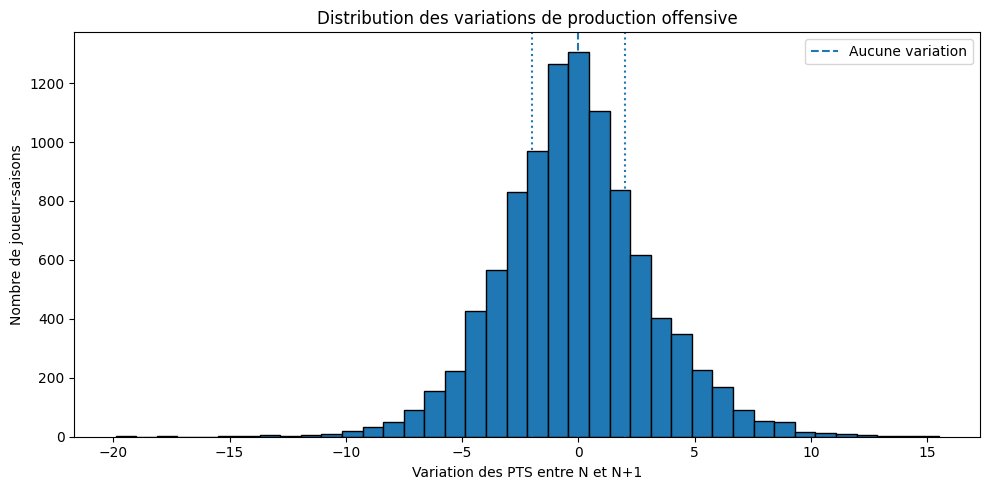

In [234]:
import matplotlib.pyplot as plt


# Distribution des variations

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    eda_dataset[
        "PTS_NEXT_CHANGE"
    ],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="Aucune variation"
)

plt.axvline(
    -2,
    linestyle=":"
)

plt.axvline(
    2,
    linestyle=":"
)

plt.xlabel(
    "Variation des PTS entre N et N+1"
)

plt.ylabel(
    "Nombre de joueur-saisons"
)

plt.title(
    "Distribution des variations de production offensive"
)

plt.legend()

plt.tight_layout()

plt.show()

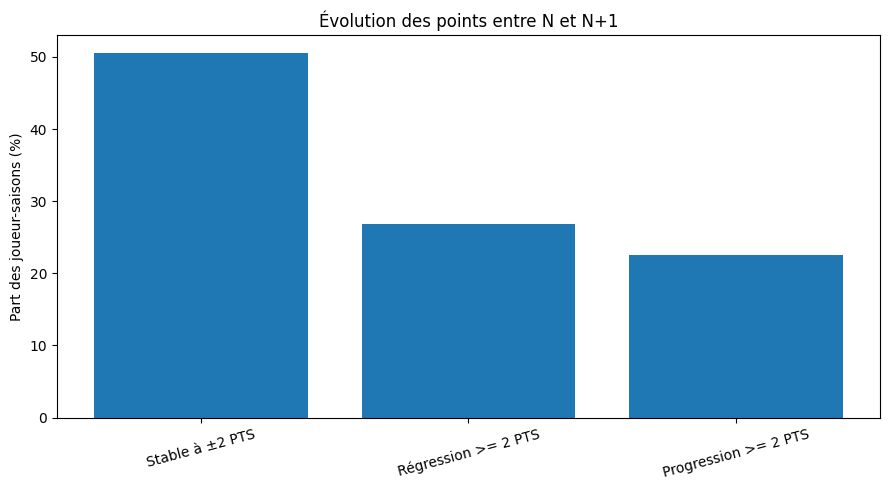

In [235]:
# Répartition progression, stabilité et régression

plot_distribution = (
    evolution_distribution
    .sort_values(
        "pourcentage",
        ascending=False
    )
)


plt.figure(
    figsize=(9, 5)
)

plt.bar(
    plot_distribution[
        "profil"
    ],
    plot_distribution[
        "pourcentage"
    ]
)

plt.ylabel(
    "Part des joueur-saisons (%)"
)

plt.title(
    "Évolution des points entre N et N+1"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.show()

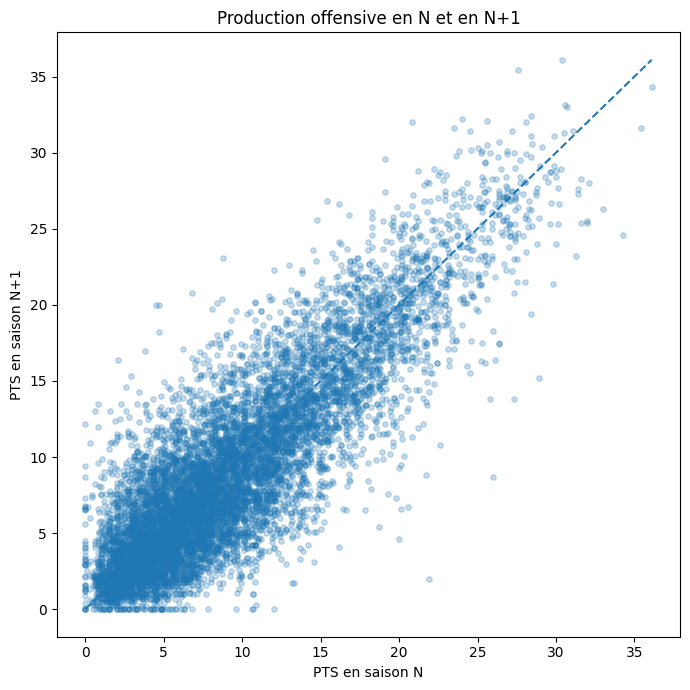

In [236]:
# Relation entre les points en N et N+1

plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    eda_dataset[
        "PTS"
    ],
    eda_dataset[
        "pts_next_season"
    ],
    alpha=0.25,
    s=15
)


max_pts = max(
    eda_dataset[
        "PTS"
    ].max(),
    eda_dataset[
        "pts_next_season"
    ].max()
)


plt.plot(
    [
        0,
        max_pts,
    ],
    [
        0,
        max_pts,
    ],
    linestyle="--"
)


plt.xlabel(
    "PTS en saison N"
)

plt.ylabel(
    "PTS en saison N+1"
)

plt.title(
    "Production offensive en N et en N+1"
)

plt.tight_layout()

plt.show()

In [237]:
# Sauvegarde des résultats de la question 1

evolution_distribution.to_csv(
    REPORT_DIR
    / "Q1_distribution_evolution.csv",
    index=False,
    encoding="utf-8"
)


change_summary.to_csv(
    REPORT_DIR
    / "Q1_resume_variations.csv",
    index=False,
    encoding="utf-8"
)


top_progressions.to_csv(
    REPORT_DIR
    / "Q1_top_progressions.csv",
    index=False,
    encoding="utf-8"
)


top_regressions.to_csv(
    REPORT_DIR
    / "Q1_top_regressions.csv",
    index=False,
    encoding="utf-8"
)

### Résultats

L'analyse porte sur 9 911 joueur-saisons disposant d'une saison N+1
consécutive.

La production offensive présente une certaine stabilité d'une saison à
l'autre :

- 50,53 % des observations restent à moins de 2 points par match de leur niveau précédent ;
- 22,59 % progressent d'au moins 2 points par match ;
- 26,88 % régressent d'au moins 2 points par match.

Parmi l'ensemble des observations, 11,87 % connaissent une variation particulièrement forte, d'au moins 5 points par match en valeur absolue.

La variation moyenne est de -0,15 point et la variation médiane de -0,20
point, ce qui indique une légère tendance globale à la baisse entre deux
saisons consécutives.

La variation absolue moyenne atteint néanmoins 2,46 points par match. Ainsi,
près d'une joueur-saison sur deux connaît une évolution d'au moins 2 points.

Les variations extrêmes vont de -19,9 à +15,5 points par match.

### Insight

La production offensive d'un joueur est globalement persistante d'une saison
à la suivante, puisque 50,53 % des joueur-saisons restent à moins de 2 points
de leur niveau précédent.

Cette stabilité n'est cependant pas suffisante pour considérer les points de
la saison N comme une prédiction parfaite de la saison N+1 : 49,47 % des
observations évoluent d'au moins 2 points et 11,87 % évoluent d'au moins
5 points.

Les régressions importantes sont légèrement plus fréquentes que les
progressions importantes, avec 26,88 % contre 22,59 %, soit un écart de
4,29 points de pourcentage.

Le niveau de points en saison N devrait donc constituer un signal prédictif
important, mais d'autres variables seront nécessaires pour identifier les
joueurs susceptibles de fortement progresser ou régresser.

### Recommandation

Le futur modèle devra utiliser le niveau de production récent du joueur comme
point de référence, notamment `PTS`, `PTS_PREV` et les moyennes historiques,
tout en intégrant des variables permettant d'expliquer les écarts à cette
continuité.

Les variables liées à l'âge, à l'expérience, au temps de jeu, au volume de
tirs, à l'usage et au contexte collectif devront notamment être étudiées afin
de déterminer si elles permettent d'anticiper les progressions et les
régressions importantes.

Une attention particulière devra également être portée aux observations dont
la variation dépasse 5 points par match, qui représentent 11,87 % du dataset
supervisé.

### Confiance et limites

**Niveau de confiance : élevé pour le constat descriptif, moyen pour
l'explication des variations.**

L'analyse repose sur 9 911 observations couvrant plusieurs saisons, ce qui
donne une base importante pour mesurer la stabilité de la production
offensive.

En revanche, les causes des progressions et régressions ne peuvent pas être
déduites de cette analyse seule. Des facteurs non présents dans le dataset,
comme les blessures, certains changements de rôle ou d'effectif, peuvent
expliquer une partie des variations extrêmes.

De plus, le dataset supervisé ne contient que les joueurs disposant d'une
saison N+1 observée. Les joueurs quittant la NBA ou ne disputant pas la saison
suivante ne sont donc pas représentés dans cette analyse.

## Question Business 2 : âge, expérience et évolution offensive

### Reformulation

**Question précise :**  
Comment l'âge et l'expérience NBA sont-ils associés à l'évolution des points
par match entre la saison N et la saison N+1 ?

**Métriques utilisées :**
- PTS en saison N ;
- PTS en saison N+1 ;
- variation `PTS_NEXT_CHANGE` ;
- variation absolue ;
- proportion de progressions et de régressions d'au moins 2 PTS.

**Granularité :**  
une ligne par joueur-saison disposant d'une saison N+1 consécutive.

L'objectif est d'identifier si certaines phases de carrière sont davantage
associées à la progression, à la stabilité ou à la régression offensive.

In [238]:
# Ordre des groupes d'âge

age_order = [
    "22_or_less",
    "23_27",
    "28_31",
    "32_plus",
]


age_analysis = (
    eda_dataset
    .groupby(
        "AGE_GROUP",
        observed=True
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        age_moyen=(
            "AGE",
            "mean"
        ),
        pts_n_moyen=(
            "PTS",
            "mean"
        ),
        pts_n1_moyen=(
            "pts_next_season",
            "mean"
        ),
        variation_moyenne=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
        variation_mediane=(
            "PTS_NEXT_CHANGE",
            "median"
        ),
        variation_absolue_moyenne=(
            "ABS_PTS_NEXT_CHANGE",
            "mean"
        ),
    )
    .reindex(
        age_order
    )
    .reset_index()
)


age_analysis[
    "progression_2pts_pct"
] = [
    (
        eda_dataset.loc[
            eda_dataset["AGE_GROUP"] == group,
            "PTS_NEXT_CHANGE"
        ]
        .ge(2)
        .mean()
        * 100
    )
    for group in age_analysis["AGE_GROUP"]
]


age_analysis[
    "regression_2pts_pct"
] = [
    (
        eda_dataset.loc[
            eda_dataset["AGE_GROUP"] == group,
            "PTS_NEXT_CHANGE"
        ]
        .le(-2)
        .mean()
        * 100
    )
    for group in age_analysis["AGE_GROUP"]
]


numeric_cols = (
    age_analysis
    .select_dtypes(
        include="number"
    )
    .columns
)


age_analysis[
    numeric_cols
] = (
    age_analysis[
        numeric_cols
    ]
    .round(2)
)


display(
    age_analysis
)

,AGE_GROUP,joueur_saisons,age_moyen,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_mediane,variation_absolue_moyenne,progression_2pts_pct,regression_2pts_pct
0,22_or_less,1475,21.17,8.18,9.65,1.47,1.3,2.75,40.81,12.81
1,23_27,4469,24.90,9.26,9.44,0.18,0.1,2.47,25.89,23.67
2,28_31,2475,29.36,10.07,9.16,-0.91,-0.9,2.38,14.99,33.41
3,32_plus,1492,33.95,8.86,7.42,-1.45,-1.3,2.29,7.31,39.54


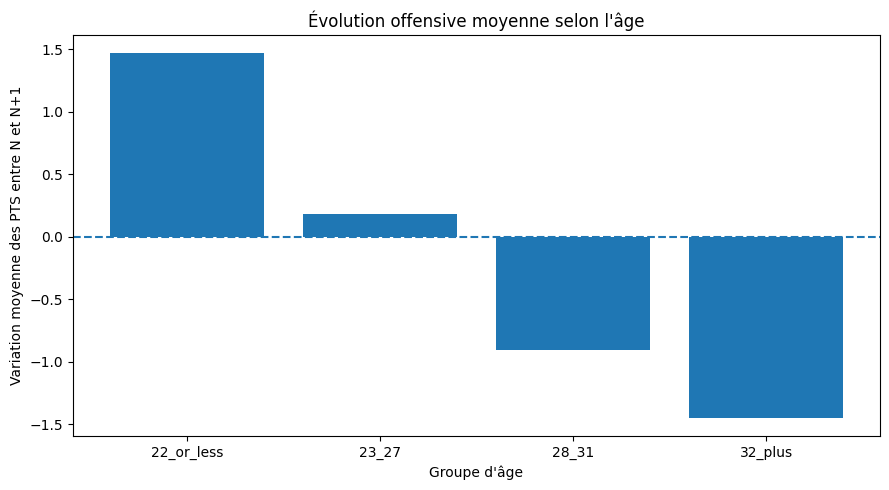

In [239]:
# Variation moyenne selon l'âge

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    age_analysis[
        "AGE_GROUP"
    ].astype(str),
    age_analysis[
        "variation_moyenne"
    ]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Groupe d'âge"
)

plt.ylabel(
    "Variation moyenne des PTS entre N et N+1"
)

plt.title(
    "Évolution offensive moyenne selon l'âge"
)

plt.tight_layout()

plt.show()

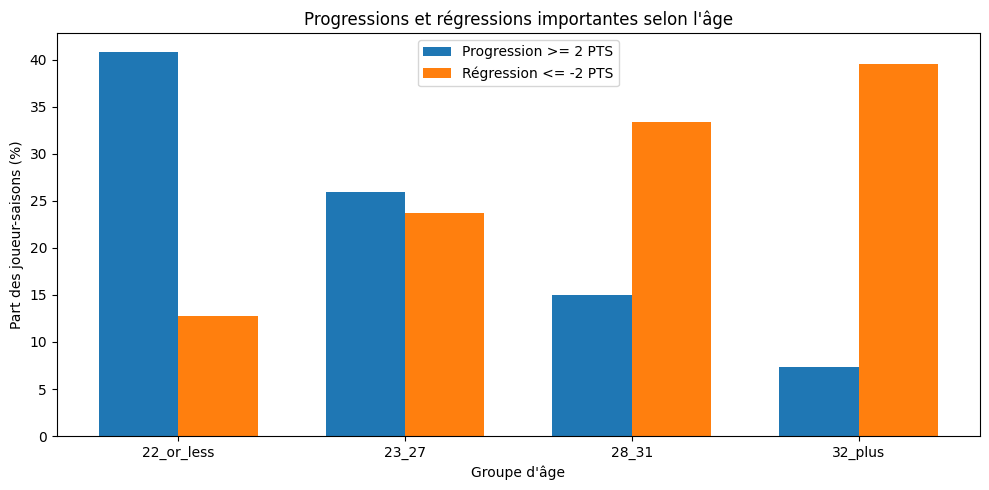

In [240]:
# Progression et régression selon l'âge

x = np.arange(
    len(age_analysis)
)

width = 0.35


plt.figure(
    figsize=(10, 5)
)

plt.bar(
    x - width / 2,
    age_analysis[
        "progression_2pts_pct"
    ],
    width,
    label="Progression >= 2 PTS"
)

plt.bar(
    x + width / 2,
    age_analysis[
        "regression_2pts_pct"
    ],
    width,
    label="Régression <= -2 PTS"
)

plt.xticks(
    x,
    age_analysis[
        "AGE_GROUP"
    ].astype(str)
)

plt.ylabel(
    "Part des joueur-saisons (%)"
)

plt.xlabel(
    "Groupe d'âge"
)

plt.title(
    "Progressions et régressions importantes selon l'âge"
)

plt.legend()

plt.tight_layout()

plt.show()

In [241]:
# Evolution par âge exact

age_curve = (
    eda_dataset
    .groupby(
        "AGE"
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        variation_moyenne=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
        variation_mediane=(
            "PTS_NEXT_CHANGE",
            "median"
        ),
    )
    .reset_index()
)


age_curve = (
    age_curve[
        age_curve[
            "joueur_saisons"
        ] >= 30
    ]
    .copy()
)


display(
    age_curve.round(2)
)

,AGE,joueur_saisons,variation_moyenne,variation_mediane
1,19.0,72,1.71,1.50
2,20.0,268,2.15,2.00
3,21.0,458,1.63,1.45
4,22.0,674,1.05,0.90
5,23.0,939,0.79,0.60
6,24.0,992,0.48,0.20
7,25.0,902,0.09,-0.10
8,26.0,853,-0.12,-0.10
9,27.0,783,-0.53,-0.50
10,28.0,719,-0.57,-0.60


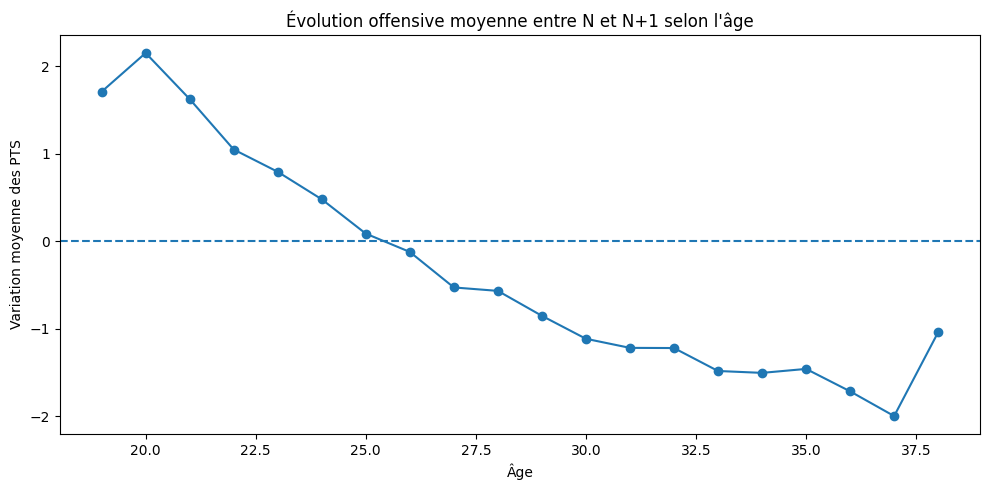

In [242]:
# Courbe de variation selon l'âge

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    age_curve[
        "AGE"
    ],
    age_curve[
        "variation_moyenne"
    ],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Âge"
)

plt.ylabel(
    "Variation moyenne des PTS"
)

plt.title(
    "Évolution offensive moyenne entre N et N+1 selon l'âge"
)

plt.tight_layout()

plt.show()

In [243]:
# Disponibilité de l'expérience

experience_dataset = (
    eda_dataset[
        eda_dataset[
            "EXPERIENCE_GROUP"
        ].notna()
    ]
    .copy()
)


print(
    "Observations totales :",
    len(eda_dataset)
)

print(
    "Expérience disponible :",
    len(experience_dataset)
)

print(
    "Expérience manquante :",
    len(eda_dataset)
    - len(experience_dataset)
)

print(
    "Couverture (%) :",
    round(
        len(experience_dataset)
        / len(eda_dataset)
        * 100,
        2
    )
)

Observations totales : 9911
Expérience disponible : 9406
Expérience manquante : 505
Couverture (%) : 94.9


In [244]:
# Analyse par niveau d'expérience

experience_order = [
    "rookie",
    "1_3_years",
    "4_7_years",
    "8_plus_years",
]


experience_analysis = (
    experience_dataset
    .groupby(
        "EXPERIENCE_GROUP",
        observed=True
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        experience_moyenne=(
            "EXP_YEARS",
            "mean"
        ),
        pts_n_moyen=(
            "PTS",
            "mean"
        ),
        pts_n1_moyen=(
            "pts_next_season",
            "mean"
        ),
        variation_moyenne=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
        variation_mediane=(
            "PTS_NEXT_CHANGE",
            "median"
        ),
        variation_absolue_moyenne=(
            "ABS_PTS_NEXT_CHANGE",
            "mean"
        ),
    )
    .reindex(
        experience_order
    )
    .reset_index()
)


experience_analysis[
    "progression_2pts_pct"
] = [
    (
        experience_dataset.loc[
            experience_dataset[
                "EXPERIENCE_GROUP"
            ] == group,
            "PTS_NEXT_CHANGE"
        ]
        .ge(2)
        .mean()
        * 100
    )
    for group in experience_analysis[
        "EXPERIENCE_GROUP"
    ]
]


experience_analysis[
    "regression_2pts_pct"
] = [
    (
        experience_dataset.loc[
            experience_dataset[
                "EXPERIENCE_GROUP"
            ] == group,
            "PTS_NEXT_CHANGE"
        ]
        .le(-2)
        .mean()
        * 100
    )
    for group in experience_analysis[
        "EXPERIENCE_GROUP"
    ]
]


numeric_cols = (
    experience_analysis
    .select_dtypes(
        include="number"
    )
    .columns
)


experience_analysis[
    numeric_cols
] = (
    experience_analysis[
        numeric_cols
    ]
    .round(2)
)


display(
    experience_analysis
)

,EXPERIENCE_GROUP,joueur_saisons,experience_moyenne,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_mediane,variation_absolue_moyenne,progression_2pts_pct,regression_2pts_pct
0,rookie,1450,0.0,5.68,6.92,1.24,0.9,2.55,36.76,12.07
1,1_3_years,3078,1.9,9.03,9.46,0.44,0.3,2.48,28.56,21.83
2,4_7_years,2741,5.37,11.11,10.53,-0.58,-0.6,2.40,18.50,30.57
3,8_plus_years,2137,10.39,10.53,9.06,-1.47,-1.4,2.42,8.84,40.48


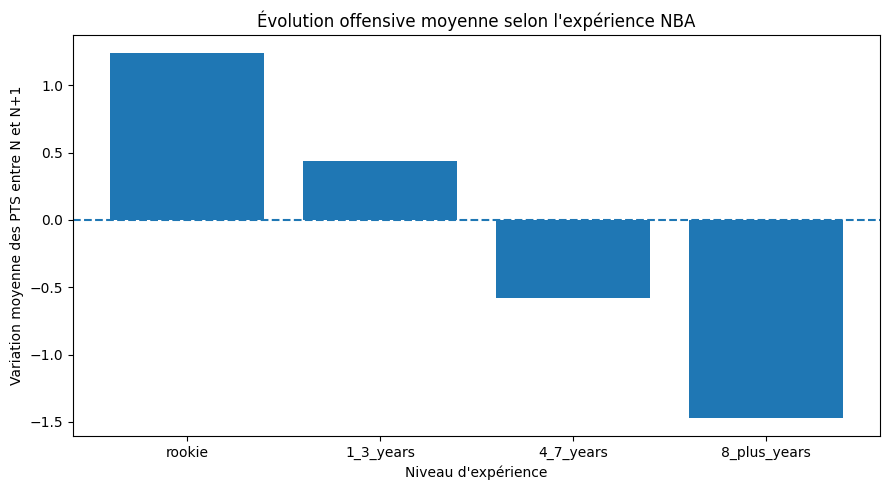

In [245]:
# Variation moyenne selon l'expérience

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    experience_analysis[
        "EXPERIENCE_GROUP"
    ].astype(str),
    experience_analysis[
        "variation_moyenne"
    ]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Niveau d'expérience"
)

plt.ylabel(
    "Variation moyenne des PTS entre N et N+1"
)

plt.title(
    "Évolution offensive moyenne selon l'expérience NBA"
)

plt.tight_layout()

plt.show()

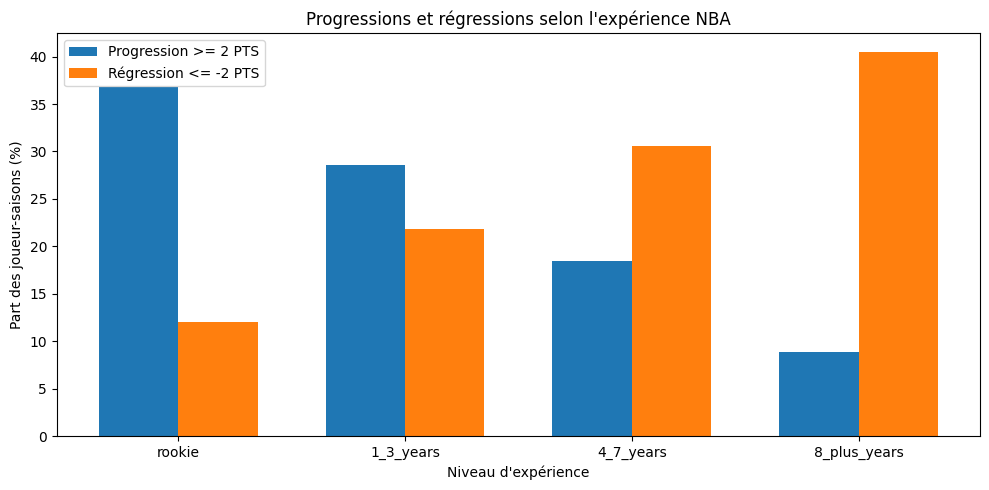

In [246]:
# Progression et régression selon l'expérience

x = np.arange(
    len(experience_analysis)
)

width = 0.35


plt.figure(
    figsize=(10, 5)
)

plt.bar(
    x - width / 2,
    experience_analysis[
        "progression_2pts_pct"
    ],
    width,
    label="Progression >= 2 PTS"
)

plt.bar(
    x + width / 2,
    experience_analysis[
        "regression_2pts_pct"
    ],
    width,
    label="Régression <= -2 PTS"
)

plt.xticks(
    x,
    experience_analysis[
        "EXPERIENCE_GROUP"
    ].astype(str)
)

plt.ylabel(
    "Part des joueur-saisons (%)"
)

plt.xlabel(
    "Niveau d'expérience"
)

plt.title(
    "Progressions et régressions selon l'expérience NBA"
)

plt.legend()

plt.tight_layout()

plt.show()

In [247]:
from scipy.stats import kruskal


# Test statistique sur les groupes d'âge

age_samples = [
    eda_dataset.loc[
        eda_dataset[
            "AGE_GROUP"
        ] == group,
        "PTS_NEXT_CHANGE"
    ].dropna()
    for group in age_order
]


age_kruskal = kruskal(
    *age_samples
)


# Test statistique sur l'expérience

experience_samples = [
    experience_dataset.loc[
        experience_dataset[
            "EXPERIENCE_GROUP"
        ] == group,
        "PTS_NEXT_CHANGE"
    ].dropna()
    for group in experience_order
]


experience_kruskal = kruskal(
    *experience_samples
)


statistical_tests = pd.DataFrame([
    {
        "analyse":
            "Variation selon l'âge",
        "test":
            "Kruskal-Wallis",
        "statistique":
            age_kruskal.statistic,
        "p_value":
            age_kruskal.pvalue,
    },
    {
        "analyse":
            "Variation selon l'expérience",
        "test":
            "Kruskal-Wallis",
        "statistique":
            experience_kruskal.statistic,
        "p_value":
            experience_kruskal.pvalue,
    },
])


statistical_tests[
    "significatif_5pct"
] = (
    statistical_tests[
        "p_value"
    ] < 0.05
)


display(
    statistical_tests
)

,analyse,test,statistique,p_value,significatif_5pct
0,Variation selon l'âge,Kruskal-Wallis,826.138662,9.273851e-179,True
1,Variation selon l'expérience,Kruskal-Wallis,801.496739,2.049398e-173,True


In [248]:
# Sauvegarde des résultats de la question 2

age_analysis.to_csv(
    REPORT_DIR
    / "Q2_analyse_age.csv",
    index=False,
    encoding="utf-8"
)


age_curve.to_csv(
    REPORT_DIR
    / "Q2_evolution_age_exact.csv",
    index=False,
    encoding="utf-8"
)


experience_analysis.to_csv(
    REPORT_DIR
    / "Q2_analyse_experience.csv",
    index=False,
    encoding="utf-8"
)


statistical_tests.to_csv(
    REPORT_DIR
    / "Q2_tests_statistiques.csv",
    index=False,
    encoding="utf-8"
)

### Résultats

L'analyse met en évidence une relation nette entre la phase de carrière du joueur
et l'évolution de sa production offensive entre la saison N et la saison N+1.

#### Âge

Les joueurs de 22 ans ou moins progressent en moyenne de **+1,47 point par match**.
Dans ce groupe :

- **40,81 %** progressent d'au moins 2 points ;
- **12,81 %** régressent d'au moins 2 points.

Chez les 23-27 ans, la production devient beaucoup plus stable :

- variation moyenne : **+0,18 point** ;
- progression d'au moins 2 points : **25,89 %** ;
- régression d'au moins 2 points : **23,67 %**.

À partir de 28 ans, la tendance moyenne devient négative :

- les 28-31 ans régressent en moyenne de **-0,91 point** ;
- les 32 ans et plus régressent en moyenne de **-1,45 point**.

Chez les 32 ans et plus, seulement **7,31 %** progressent d'au moins 2 points,
contre **39,54 %** qui régressent d'au moins 2 points.

L'analyse par âge précis montre une transition progressive. La variation moyenne
est fortement positive chez les joueurs les plus jeunes, puis diminue presque
continuellement avec l'âge. Elle devient proche de zéro autour de **25-26 ans**,
puis reste globalement négative aux âges supérieurs.

La baisse n'est cependant pas parfaitement régulière aux âges les plus élevés.
La variation moyenne passe notamment d'environ **-2,00 points à 37 ans** à
**-1,04 point à 38 ans**.

Cette remontée ne doit pas être interprétée comme un rebond général des
performances après 37 ans. Les effectifs deviennent faibles à ces âges :
l'analyse repose sur seulement **78 joueur-saisons à 37 ans** et **47 à 38 ans**.
La moyenne est donc beaucoup plus sensible à quelques observations particulières.

#### Expérience NBA

La même tendance apparaît lorsque les joueurs sont regroupés selon leur
expérience NBA :

- rookies : **+1,24 point** en moyenne ;
- 1 à 3 ans d'expérience : **+0,44 point** ;
- 4 à 7 ans : **-0,58 point** ;
- 8 ans ou plus : **-1,47 point**.

Chez les rookies, **36,76 %** progressent d'au moins 2 points contre seulement
**12,07 %** de régressions.

À l'inverse, chez les joueurs ayant 8 années d'expérience ou plus, seulement
**8,84 %** progressent d'au moins 2 points, tandis que **40,48 %** régressent
d'au moins 2 points.

L'information d'expérience est disponible pour **9 406 des 9 911 observations**,
soit une couverture de **94,9 %**.

Les tests de Kruskal-Wallis indiquent que les distributions des variations
diffèrent significativement entre les groupes d'âge et entre les groupes
d'expérience, avec une **p-value très inférieure à 0,001** dans les deux cas.

### Insight

La phase de carrière est fortement associée à l'évolution offensive d'un joueur.

Les joueurs les plus jeunes présentent une probabilité de progression nettement
supérieure à leur probabilité de régression. Chez les 22 ans ou moins,
**40,81 %** progressent d'au moins 2 points contre **12,81 %** qui régressent,
soit environ **3,2 fois plus de progressions que de régressions**.

La situation s'inverse chez les joueurs de 32 ans et plus : **39,54 %**
régressent d'au moins 2 points contre seulement **7,31 %** qui progressent,
soit environ **5,4 fois plus de régressions que de progressions**.

L'expérience montre une dynamique comparable. Les premières saisons NBA sont
davantage associées à la progression, alors que les joueurs les plus expérimentés
présentent beaucoup plus fréquemment une baisse de production.

Les résultats suggèrent donc une relation non linéaire entre la phase de carrière
et la performance future, avec une zone de relative stabilité autour du milieu
de la vingtaine puis une tendance moyenne au déclin.

La remontée observée à 38 ans ne remet pas en cause cette tendance générale,
car elle repose sur un échantillon très réduit et peut refléter un effet de
sélection : les joueurs encore présents en NBA à un âge aussi avancé constituent
un groupe particulier de vétérans ayant réussi à prolonger leur carrière.

### Recommandation

Le futur modèle devrait intégrer l'âge et l'expérience comme variables
explicatives importantes, sans supposer que leur relation avec la cible est
strictement linéaire.

Les variables `AGE_GROUP` et `EXPERIENCE_GROUP` créées en Phase 4 sont donc
pertinentes pour représenter différentes phases de carrière :

- développement ;
- relative stabilité ;
- déclin plus fréquent.

Il sera également intéressant d'étudier les interactions entre âge, expérience,
production actuelle et rôle offensif afin de distinguer, par exemple, un jeune
joueur en développement d'un vétéran maintenant encore un rôle important.

### Confiance et limites

**Niveau de confiance : élevé pour l'association globale observée.**

Les tendances sont cohérentes entre les analyses par âge et par expérience et
les différences entre groupes sont statistiquement significatives.

Cependant, cette analyse ne permet pas d'établir une relation causale.
L'âge et l'expérience sont fortement corrélés entre eux et représentent en
grande partie la même progression de carrière.

Les effectifs diminuent également fortement aux âges les plus élevés. Les
résultats observés à 37 ou 38 ans sont donc beaucoup moins robustes que ceux des
groupes les plus représentés.

Un effet de sélection est également possible : les joueurs capables de rester
en NBA jusqu'à un âge très avancé peuvent avoir des profils différents de ceux
ayant quitté la ligue plus tôt.

Enfin, **505 observations** ne disposent pas de l'information d'expérience et
sont exclues de cette partie de l'analyse.

## Question Business 3 : rôle offensif et performance future

### Reformulation

**Question précise :**  
Dans quelle mesure le rôle offensif occupé par un joueur en saison N est-il
associé à sa production de points en saison N+1 ?

**Variables étudiées :**
- `MIN` : temps de jeu moyen ;
- `FGA` : volume de tirs tentés ;
- `USG_PCT` : part des possessions utilisées par le joueur ;
- `pts_next_season` : production offensive en N+1 ;
- `PTS_NEXT_CHANGE` : évolution des points entre N et N+1.

**Granularité :**  
une ligne par joueur-saison disposant d'une saison N+1 consécutive.

L'objectif est de distinguer deux phénomènes :
1. les variables associées à un niveau de points élevé en N+1 ;
2. les variables associées à une progression ou une régression entre N et N+1.

In [249]:
# Vérification des variables de rôle offensif

role_features = [
    "MIN",
    "FGA",
    "USG_PCT",
]


role_feature_summary = (
    eda_dataset[
        role_features
    ]
    .describe()
    .T[
        [
            "count",
            "mean",
            "50%",
            "min",
            "max",
        ]
    ]
    .round(3)
)


display(
    role_feature_summary
)

,count,mean,50%,min,max
MIN,9911.0,22.317,22.400,0.2,43.700
FGA,9911.0,7.629,6.700,0.0,27.800
USG_PCT,9911.0,0.185,0.181,0.0,0.667


In [250]:
from scipy.stats import pearsonr, spearmanr


# Corrélations des variables de rôle

role_correlation_rows = []


for feature in role_features:

    target_data = (
        eda_dataset[
            [
                feature,
                "pts_next_season",
                "PTS_NEXT_CHANGE",
            ]
        ]
        .dropna()
    )


    pearson_target = pearsonr(
        target_data[feature],
        target_data["pts_next_season"]
    )


    spearman_target = spearmanr(
        target_data[feature],
        target_data["pts_next_season"]
    )


    pearson_change = pearsonr(
        target_data[feature],
        target_data["PTS_NEXT_CHANGE"]
    )


    spearman_change = spearmanr(
        target_data[feature],
        target_data["PTS_NEXT_CHANGE"]
    )


    role_correlation_rows.append({
        "feature": feature,
        "pearson_cible": pearson_target.statistic,
        "spearman_cible": spearman_target.statistic,
        "pearson_variation": pearson_change.statistic,
        "spearman_variation": spearman_change.statistic,
    })


role_correlations = pd.DataFrame(
    role_correlation_rows
)


correlation_columns = [
    col
    for col in role_correlations.columns
    if col != "feature"
]


role_correlations[
    correlation_columns
] = (
    role_correlations[
        correlation_columns
    ]
    .round(3)
)


display(
    role_correlations
)

,feature,pearson_cible,spearman_cible,pearson_variation,spearman_variation
0,MIN,0.718,0.731,-0.263,-0.252
1,FGA,0.838,0.797,-0.225,-0.236
2,USG_PCT,0.668,0.607,-0.092,-0.080


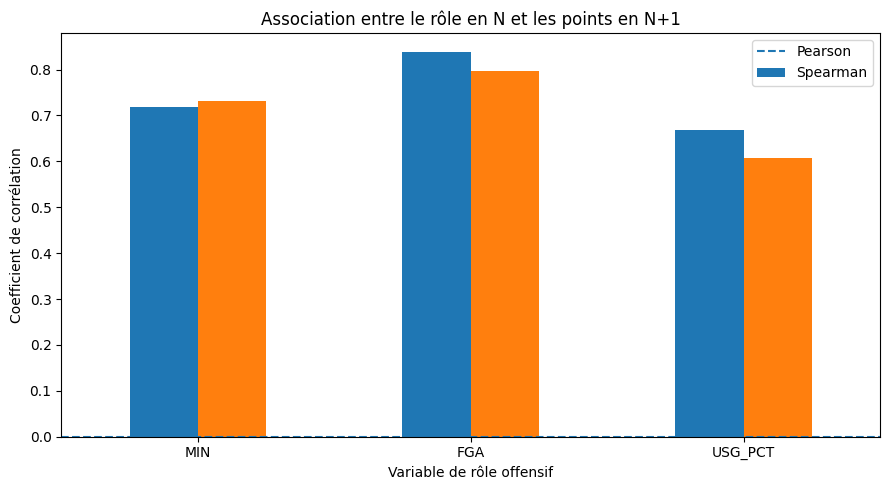

In [251]:
# Corrélations avec la production en N+1

plot_data = (
    role_correlations
    .set_index(
        "feature"
    )[
        [
            "pearson_cible",
            "spearman_cible",
        ]
    ]
)


plot_data.plot(
    kind="bar",
    figsize=(9, 5)
)


plt.axhline(
    0,
    linestyle="--"
)

plt.ylabel(
    "Coefficient de corrélation"
)

plt.xlabel(
    "Variable de rôle offensif"
)

plt.title(
    "Association entre le rôle en N et les points en N+1"
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "Pearson",
        "Spearman",
    ]
)

plt.tight_layout()

plt.show()

In [252]:
# Segmentation selon le temps de jeu

eda_dataset[
    "MIN_GROUP"
] = pd.cut(
    eda_dataset[
        "MIN"
    ],
    bins=[
        -np.inf,
        15,
        25,
        32,
        np.inf,
    ],
    labels=[
        "< 15 min",
        "15-25 min",
        "25-32 min",
        "32+ min",
    ],
    right=False,
)


min_analysis = (
    eda_dataset
    .groupby(
        "MIN_GROUP",
        observed=True
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        min_moyen=(
            "MIN",
            "mean"
        ),
        pts_n_moyen=(
            "PTS",
            "mean"
        ),
        pts_n1_moyen=(
            "pts_next_season",
            "mean"
        ),
        variation_moyenne=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
        variation_absolue_moyenne=(
            "ABS_PTS_NEXT_CHANGE",
            "mean"
        ),
    )
    .reset_index()
)


display(
    min_analysis.round(2)
)

,MIN_GROUP,joueur_saisons,min_moyen,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_absolue_moyenne
0,< 15 min,2505,9.94,3.19,4.34,1.15,2.08
1,15-25 min,3291,19.94,7.12,6.96,-0.17,2.41
2,25-32 min,2200,28.47,11.70,10.91,-0.79,2.77
3,32+ min,1915,35.52,17.98,16.91,-1.07,2.70


In [253]:
# Segmentation selon le volume de tirs

eda_dataset[
    "FGA_GROUP"
] = pd.cut(
    eda_dataset[
        "FGA"
    ],
    bins=[
        -np.inf,
        5,
        10,
        15,
        np.inf,
    ],
    labels=[
        "< 5 tirs",
        "5-10 tirs",
        "10-15 tirs",
        "15+ tirs",
    ],
    right=False,
)


fga_analysis = (
    eda_dataset
    .groupby(
        "FGA_GROUP",
        observed=True
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        fga_moyen=(
            "FGA",
            "mean"
        ),
        pts_n_moyen=(
            "PTS",
            "mean"
        ),
        pts_n1_moyen=(
            "pts_next_season",
            "mean"
        ),
        variation_moyenne=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
        variation_absolue_moyenne=(
            "ABS_PTS_NEXT_CHANGE",
            "mean"
        ),
    )
    .reset_index()
)


display(
    fga_analysis.round(2)
)

,FGA_GROUP,joueur_saisons,fga_moyen,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_absolue_moyenne
0,< 5 tirs,3415,3.11,3.60,4.44,0.84,2.04
1,5-10 tirs,3748,7.20,8.62,8.20,-0.41,2.53
2,10-15 tirs,1887,12.13,14.81,13.84,-0.97,2.89
3,15+ tirs,861,17.53,22.14,21.06,-1.09,2.94


In [254]:
# Normalisation de l'usage pour l'analyse

if (
    eda_dataset[
        "USG_PCT"
    ].median()
    <= 1
):

    eda_dataset[
        "USG_PERCENT"
    ] = (
        eda_dataset[
            "USG_PCT"
        ]
        * 100
    )

else:

    eda_dataset[
        "USG_PERCENT"
    ] = (
        eda_dataset[
            "USG_PCT"
        ]
    )


print(
    eda_dataset[
        "USG_PERCENT"
    ]
    .describe()
    .round(2)
)

count    9911.00
mean       18.53
std         5.02
min         0.00
25%        15.00
50%        18.10
75%        21.60
max        66.70
Name: USG_PERCENT, dtype: float64


In [255]:
# Segmentation selon l'usage offensif

eda_dataset[
    "USG_GROUP"
] = pd.cut(
    eda_dataset[
        "USG_PERCENT"
    ],
    bins=[
        -np.inf,
        15,
        20,
        25,
        np.inf,
    ],
    labels=[
        "< 15 %",
        "15-20 %",
        "20-25 %",
        "25+ %",
    ],
    right=False,
)


usg_analysis = (
    eda_dataset
    .groupby(
        "USG_GROUP",
        observed=True
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        usage_moyen=(
            "USG_PERCENT",
            "mean"
        ),
        pts_n_moyen=(
            "PTS",
            "mean"
        ),
        pts_n1_moyen=(
            "pts_next_season",
            "mean"
        ),
        variation_moyenne=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
        variation_absolue_moyenne=(
            "ABS_PTS_NEXT_CHANGE",
            "mean"
        ),
    )
    .reset_index()
)


display(
    usg_analysis.round(2)
)

,USG_GROUP,joueur_saisons,usage_moyen,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_absolue_moyenne
0,< 15 %,2413,12.55,4.74,4.91,0.17,1.92
1,15-20 %,4000,17.46,7.64,7.59,-0.06,2.45
2,20-25 %,2470,22.15,12.03,11.72,-0.32,2.76
3,25+ %,1028,28.09,19.34,18.51,-0.82,3.08


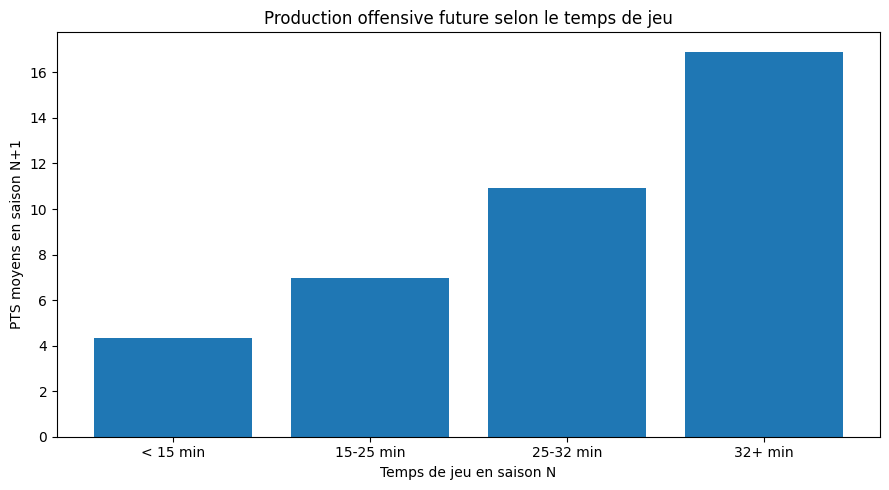

In [256]:
# Production future selon le temps de jeu

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    min_analysis[
        "MIN_GROUP"
    ].astype(str),
    min_analysis[
        "pts_n1_moyen"
    ]
)

plt.xlabel(
    "Temps de jeu en saison N"
)

plt.ylabel(
    "PTS moyens en saison N+1"
)

plt.title(
    "Production offensive future selon le temps de jeu"
)

plt.tight_layout()

plt.show()

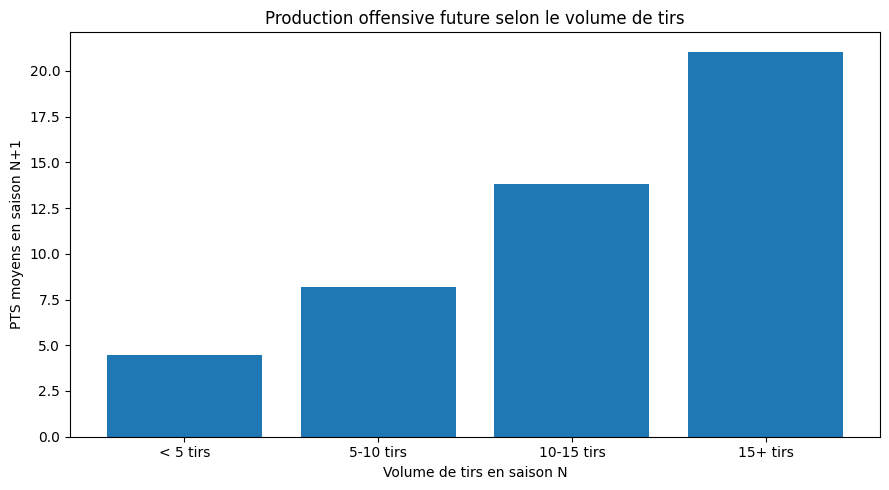

In [257]:
# Production future selon le volume de tirs

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    fga_analysis[
        "FGA_GROUP"
    ].astype(str),
    fga_analysis[
        "pts_n1_moyen"
    ]
)

plt.xlabel(
    "Volume de tirs en saison N"
)

plt.ylabel(
    "PTS moyens en saison N+1"
)

plt.title(
    "Production offensive future selon le volume de tirs"
)

plt.tight_layout()

plt.show()

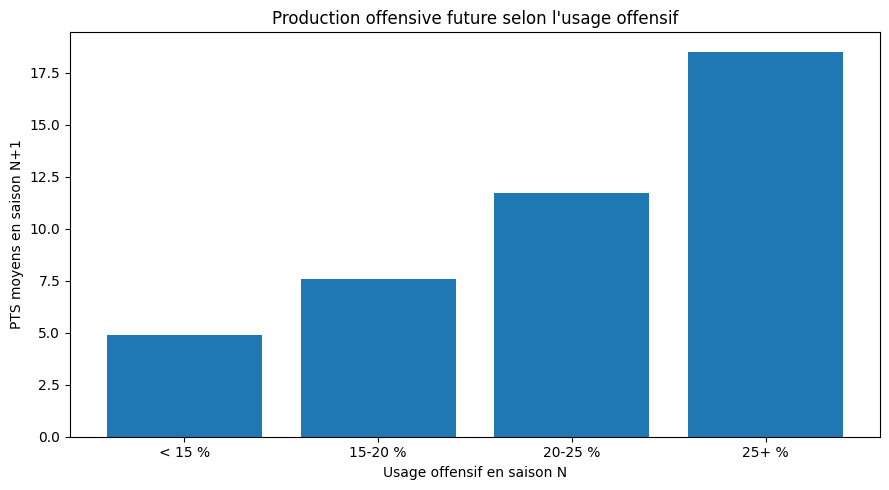

In [258]:
# Production future selon l'usage offensif

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    usg_analysis[
        "USG_GROUP"
    ].astype(str),
    usg_analysis[
        "pts_n1_moyen"
    ]
)

plt.xlabel(
    "Usage offensif en saison N"
)

plt.ylabel(
    "PTS moyens en saison N+1"
)

plt.title(
    "Production offensive future selon l'usage offensif"
)

plt.tight_layout()

plt.show()

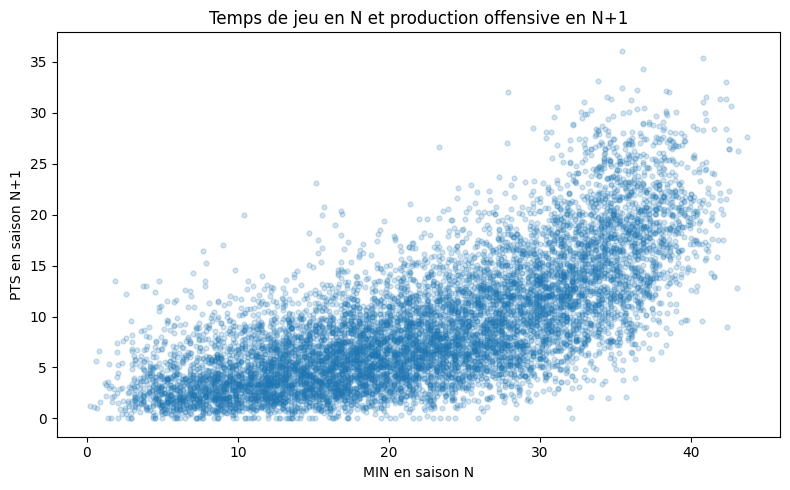

In [259]:
# Temps de jeu et points en N+1

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    eda_dataset[
        "MIN"
    ],
    eda_dataset[
        "pts_next_season"
    ],
    alpha=0.2,
    s=12
)

plt.xlabel(
    "MIN en saison N"
)

plt.ylabel(
    "PTS en saison N+1"
)

plt.title(
    "Temps de jeu en N et production offensive en N+1"
)

plt.tight_layout()

plt.show()

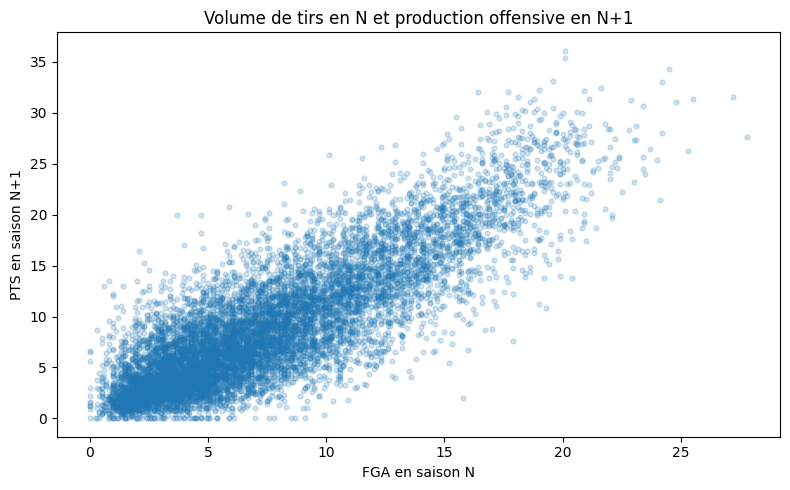

In [260]:
# Volume de tirs et points en N+1

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    eda_dataset[
        "FGA"
    ],
    eda_dataset[
        "pts_next_season"
    ],
    alpha=0.2,
    s=12
)

plt.xlabel(
    "FGA en saison N"
)

plt.ylabel(
    "PTS en saison N+1"
)

plt.title(
    "Volume de tirs en N et production offensive en N+1"
)

plt.tight_layout()

plt.show()

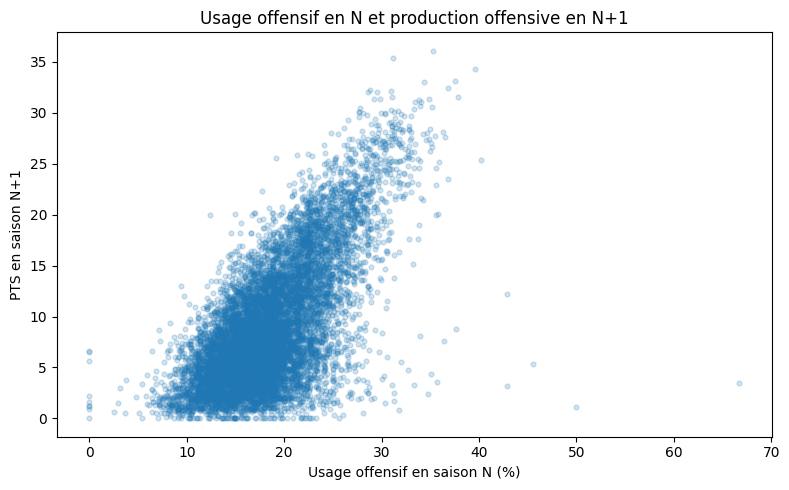

In [261]:
# Usage offensif et points en N+1

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    eda_dataset[
        "USG_PERCENT"
    ],
    eda_dataset[
        "pts_next_season"
    ],
    alpha=0.2,
    s=12
)

plt.xlabel(
    "Usage offensif en saison N (%)"
)

plt.ylabel(
    "PTS en saison N+1"
)

plt.title(
    "Usage offensif en N et production offensive en N+1"
)

plt.tight_layout()

plt.show()

In [262]:
from scipy.stats import kruskal


# Tests entre les groupes de rôle offensif

min_samples = [
    group[
        "pts_next_season"
    ].dropna()
    for _, group in eda_dataset.groupby(
        "MIN_GROUP",
        observed=True
    )
]


fga_samples = [
    group[
        "pts_next_season"
    ].dropna()
    for _, group in eda_dataset.groupby(
        "FGA_GROUP",
        observed=True
    )
]


usg_samples = [
    group[
        "pts_next_season"
    ].dropna()
    for _, group in eda_dataset.groupby(
        "USG_GROUP",
        observed=True
    )
]


min_test = kruskal(
    *min_samples
)

fga_test = kruskal(
    *fga_samples
)

usg_test = kruskal(
    *usg_samples
)


role_tests = pd.DataFrame([
    {
        "variable": "MIN",
        "statistique": min_test.statistic,
        "p_value": min_test.pvalue,
    },
    {
        "variable": "FGA",
        "statistique": fga_test.statistic,
        "p_value": fga_test.pvalue,
    },
    {
        "variable": "USG_PCT",
        "statistique": usg_test.statistic,
        "p_value": usg_test.pvalue,
    },
])


role_tests[
    "significatif_5pct"
] = (
    role_tests[
        "p_value"
    ]
    < 0.05
)


display(
    role_tests
)

,variable,statistique,p_value,significatif_5pct
0,MIN,5055.865060,0.0,True
1,FGA,5800.448608,0.0,True
2,USG_PCT,3414.575311,0.0,True


In [263]:
# Sauvegarde des résultats de la question 3

role_correlations.to_csv(
    REPORT_DIR
    / "Q3_correlations_role.csv",
    index=False,
    encoding="utf-8"
)


min_analysis.to_csv(
    REPORT_DIR
    / "Q3_analyse_minutes.csv",
    index=False,
    encoding="utf-8"
)


fga_analysis.to_csv(
    REPORT_DIR
    / "Q3_analyse_tirs.csv",
    index=False,
    encoding="utf-8"
)


usg_analysis.to_csv(
    REPORT_DIR
    / "Q3_analyse_usage.csv",
    index=False,
    encoding="utf-8"
)


role_tests.to_csv(
    REPORT_DIR
    / "Q3_tests_statistiques.csv",
    index=False,
    encoding="utf-8"
)

### Résultats

L'analyse montre une association forte entre le rôle offensif occupé par un
joueur en saison N et son niveau de points en saison N+1.

#### Corrélations avec les points en N+1

Parmi les trois variables étudiées, le volume de tirs `FGA` présente la relation
la plus forte avec la cible :

- `FGA` : Pearson = **0,838**, Spearman = **0,797** ;
- `MIN` : Pearson = **0,718**, Spearman = **0,731** ;
- `USG_PCT` : Pearson = **0,668**, Spearman = **0,607**.

Les coefficients de Pearson et de Spearman sont proches et tous positifs.
Cela indique que les joueurs qui tirent davantage, jouent davantage de minutes
et occupent une part plus importante des possessions en saison N ont tendance
à conserver un niveau de production offensive élevé en saison N+1.

Le volume de tirs apparaît comme le signal le plus fortement associé aux points
de la saison suivante parmi les trois variables étudiées.

#### Temps de jeu

La production moyenne en N+1 augmente fortement avec le temps de jeu observé
en N :

- moins de 15 minutes : **4,34 PTS** en N+1 ;
- 15 à 25 minutes : **6,96 PTS** ;
- 25 à 32 minutes : **10,91 PTS** ;
- 32 minutes ou plus : **16,91 PTS**.

Les joueurs disposant de 32 minutes ou plus en N marquent donc en moyenne près
de **3,9 fois plus** de points en N+1 que ceux jouant moins de 15 minutes.

#### Volume de tirs

La relation est encore plus marquée pour le nombre de tirs tentés :

- moins de 5 tirs : **4,44 PTS** en N+1 ;
- 5 à 10 tirs : **8,20 PTS** ;
- 10 à 15 tirs : **13,84 PTS** ;
- 15 tirs ou plus : **21,06 PTS**.

Les joueurs tentant au moins 15 tirs par match en N marquent ainsi environ
**4,7 fois plus** en N+1 que ceux tentant moins de 5 tirs.

#### Usage offensif

La même progression est observée avec l'usage :

- moins de 15 % : **4,91 PTS** en N+1 ;
- 15 à 20 % : **7,59 PTS** ;
- 20 à 25 % : **11,72 PTS** ;
- 25 % ou plus : **18,51 PTS**.

Un usage offensif élevé en saison N est donc fortement associé à une production
élevée lors de la saison suivante.

Les tests de Kruskal-Wallis montrent que les différences entre les groupes de
minutes, de tirs et d'usage sont statistiquement significatives, avec des
p-values très inférieures à **0,05**.

### Niveau futur et progression future

L'analyse de `PTS_NEXT_CHANGE` apporte cependant une nuance importante.

Les corrélations entre le rôle en N et la variation des points entre N et N+1
sont négatives et nettement plus faibles :

- `MIN` : Pearson = **-0,263** ;
- `FGA` : Pearson = **-0,225** ;
- `USG_PCT` : Pearson = **-0,092**.

Ainsi, un rôle offensif important est fortement associé à un niveau de points
élevé en N+1, mais pas à une progression supplémentaire.

Par exemple :

- les joueurs tentant moins de 5 tirs progressent en moyenne de **+0,84 PTS** ;
- les joueurs tentant 15 tirs ou plus régressent en moyenne de **-1,09 PTS**.

La même tendance apparaît avec le temps de jeu :

- moins de 15 minutes : **+1,15 PTS** ;
- 32 minutes ou plus : **-1,07 PTS**.

Et avec l'usage :

- moins de 15 % : **+0,17 PTS** ;
- 25 % ou plus : **-0,82 PTS**.

### Insight

Le rôle offensif actuel constitue un signal particulièrement important pour
estimer le niveau de production d'un joueur lors de la saison suivante.

Le volume de tirs est la variable la plus fortement associée à
`pts_next_season`, devant le temps de jeu et l'usage offensif.

Cependant, ces variables semblent surtout indiquer le **niveau offensif déjà
atteint par le joueur**, et beaucoup moins sa capacité à progresser davantage.

Les joueurs ayant déjà un rôle majeur conservent généralement une production
élevée en N+1, mais leur marge de progression moyenne est plus faible. À
l'inverse, les joueurs disposant d'un rôle limité peuvent plus facilement
augmenter leur production lors de la saison suivante.

Cette différence est importante pour le futur modèle : prédire un niveau élevé
en N+1 et prédire une forte progression entre N et N+1 sont deux problèmes
liés mais différents.

### Recommandation

Le futur modèle devrait accorder une importance particulière aux variables
représentant le rôle offensif actuel du joueur, notamment :

- `FGA` ;
- `MIN` ;
- `USG_PCT` ;
- ainsi que les variables dérivées associées au volume et à l'historique.

`FGA` semble particulièrement prometteuse pour prédire le niveau de points en
N+1.

Il sera cependant nécessaire de combiner ces informations avec les variables
d'âge, d'expérience et d'évolution récente afin de mieux identifier les joueurs
susceptibles de progresser ou de régresser.

Les interactions entre rôle offensif et phase de carrière pourront notamment
être étudiées lors de la modélisation.

### Confiance et limites

**Niveau de confiance : élevé pour l'association avec le niveau de production
future, moyen pour l'interprétation des variations.**

Les relations sont fortes, cohérentes entre les segmentations et les
corrélations, et les différences entre groupes sont statistiquement
significatives.

Cependant, ces résultats représentent des associations et non des relations
causales.

Les minutes, le volume de tirs, l'usage et les points sont fortement liés entre
eux. Un joueur peut par exemple recevoir davantage de tirs précisément parce
qu'il est déjà considéré comme un meilleur scoreur.

Il existe donc une forte redondance entre plusieurs indicateurs de rôle
offensif, qui devra être prise en compte lors de la sélection des variables du
modèle.

Enfin, la légère tendance à la régression observée chez les joueurs possédant
déjà un rôle important peut en partie refléter un effet de retour vers un niveau
plus habituel après une saison particulièrement productive. Cette hypothèse
devra être vérifiée avec les autres variables historiques et lors de la
modélisation.

## Question Business 4 : contexte collectif et performance future

### Reformulation

**Question précise :**  
Dans quelle mesure le contexte collectif de l'équipe en saison N est-il associé
à la production offensive du joueur en saison N+1 ?

**Variables étudiées :**
- pourcentage de victoires de l'équipe ;
- efficacité offensive ;
- net rating ;
- rythme de jeu ;
- points du joueur en saison N+1 ;
- évolution des points entre N et N+1.

**Granularité :**  
une ligne par joueur-saison disposant d'une saison N+1 consécutive.

L'analyse principale est limitée aux joueur-saisons passées dans une seule
équipe afin d'éviter l'ambiguïté liée aux joueurs transférés en cours de saison.

In [264]:
# Variables de contexte collectif disponibles

team_candidates = [
    "TEAM_W_PCT",
    "TEAM_OFF_RATING",
    "TEAM_DEF_RATING",
    "TEAM_NET_RATING",
    "TEAM_PACE",
]


team_features = [
    col
    for col in team_candidates
    if col in eda_dataset.columns
]


print(
    "Variables équipe disponibles :",
    team_features
)


team_feature_summary = (
    eda_dataset[
        team_features
    ]
    .describe()
    .T[
        [
            "count",
            "mean",
            "50%",
            "min",
            "max",
        ]
    ]
    .round(3)
)


display(
    team_feature_summary
)

Variables équipe disponibles : ['TEAM_W_PCT', 'TEAM_OFF_RATING', 'TEAM_DEF_RATING', 'TEAM_NET_RATING', 'TEAM_PACE']


,count,mean,50%,min,max
TEAM_W_PCT,9911.0,0.503,0.512,0.106,0.89
TEAM_OFF_RATING,9911.0,105.715,105.400,91.200,117.30
TEAM_DEF_RATING,9911.0,105.620,105.600,93.100,116.80
TEAM_NET_RATING,9911.0,0.092,0.300,-15.000,11.80
TEAM_PACE,9911.0,94.495,93.900,84.310,105.51


In [265]:
# Joueurs associés à une seule équipe sur la saison

team_eda_dataset = (
    eda_dataset[
        eda_dataset[
            "MULTI_TEAM_SEASON"
        ] == 0
    ]
    .copy()
)


print(
    "Observations totales :",
    len(eda_dataset)
)

print(
    "Observations mono-équipe :",
    len(team_eda_dataset)
)

print(
    "Observations multi-équipe exclues :",
    len(eda_dataset)
    - len(team_eda_dataset)
)

print(
    "Couverture (%) :",
    round(
        len(team_eda_dataset)
        / len(eda_dataset)
        * 100,
        2
    )
)

Observations totales : 9911
Observations mono-équipe : 8829
Observations multi-équipe exclues : 1082
Couverture (%) : 89.08


In [266]:
from scipy.stats import pearsonr, spearmanr


# Corrélations du contexte collectif

team_correlation_rows = []


for feature in team_features:

    data = (
        team_eda_dataset[
            [
                feature,
                "pts_next_season",
                "PTS_NEXT_CHANGE",
            ]
        ]
        .dropna()
    )


    pearson_target = pearsonr(
        data[feature],
        data["pts_next_season"]
    )

    spearman_target = spearmanr(
        data[feature],
        data["pts_next_season"]
    )

    pearson_change = pearsonr(
        data[feature],
        data["PTS_NEXT_CHANGE"]
    )

    spearman_change = spearmanr(
        data[feature],
        data["PTS_NEXT_CHANGE"]
    )


    team_correlation_rows.append({
        "feature": feature,
        "pearson_cible": pearson_target.statistic,
        "spearman_cible": spearman_target.statistic,
        "pearson_variation": pearson_change.statistic,
        "spearman_variation": spearman_change.statistic,
    })


team_correlations = pd.DataFrame(
    team_correlation_rows
)


numeric_cols = [
    col
    for col in team_correlations.columns
    if col != "feature"
]


team_correlations[
    numeric_cols
] = (
    team_correlations[
        numeric_cols
    ]
    .round(3)
)


display(
    team_correlations
)

,feature,pearson_cible,spearman_cible,pearson_variation,spearman_variation
0,TEAM_W_PCT,0.049,0.032,0.125,0.123
1,TEAM_OFF_RATING,0.094,0.074,0.084,0.080
2,TEAM_DEF_RATING,0.043,0.043,-0.051,-0.048
3,TEAM_NET_RATING,0.048,0.031,0.121,0.121
4,TEAM_PACE,0.077,0.067,0.006,0.009


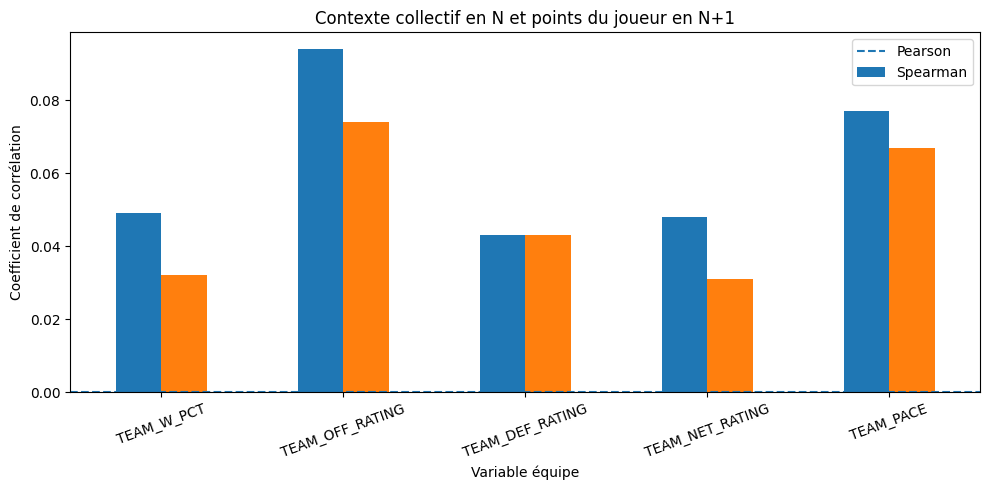

In [267]:
# Association entre contexte équipe et points en N+1

plot_team_corr = (
    team_correlations
    .set_index(
        "feature"
    )[
        [
            "pearson_cible",
            "spearman_cible",
        ]
    ]
)


plot_team_corr.plot(
    kind="bar",
    figsize=(10, 5)
)


plt.axhline(
    0,
    linestyle="--"
)

plt.ylabel(
    "Coefficient de corrélation"
)

plt.xlabel(
    "Variable équipe"
)

plt.title(
    "Contexte collectif en N et points du joueur en N+1"
)

plt.xticks(
    rotation=20
)

plt.legend(
    [
        "Pearson",
        "Spearman",
    ]
)

plt.tight_layout()

plt.show()

In [268]:
# Segmentation de l'efficacité offensive de l'équipe

if (
    "TEAM_OFF_RATING"
    in team_eda_dataset.columns
):

    team_eda_dataset[
        "TEAM_OFF_RATING_GROUP"
    ] = pd.qcut(
        team_eda_dataset[
            "TEAM_OFF_RATING"
        ],
        q=4,
        labels=[
            "Q1 - faible",
            "Q2",
            "Q3",
            "Q4 - élevée",
        ],
        duplicates="drop"
    )


    team_off_analysis = (
        team_eda_dataset
        .groupby(
            "TEAM_OFF_RATING_GROUP",
            observed=True
        )
        .agg(
            joueur_saisons=(
                "PLAYER_ID",
                "count"
            ),
            off_rating_moyen=(
                "TEAM_OFF_RATING",
                "mean"
            ),
            pts_n_moyen=(
                "PTS",
                "mean"
            ),
            pts_n1_moyen=(
                "pts_next_season",
                "mean"
            ),
            variation_moyenne=(
                "PTS_NEXT_CHANGE",
                "mean"
            ),
            variation_absolue_moyenne=(
                "ABS_PTS_NEXT_CHANGE",
                "mean"
            ),
        )
        .reset_index()
    )


    display(
        team_off_analysis.round(2)
    )

,TEAM_OFF_RATING_GROUP,joueur_saisons,off_rating_moyen,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_absolue_moyenne
0,Q1 - faible,2235,100.45,9.05,8.63,-0.43,2.55
1,Q2,2281,104.17,9.36,9.18,-0.18,2.56
2,Q3,2123,107.04,9.44,9.41,-0.03,2.42
3,Q4 - élevée,2190,111.50,9.85,10.08,0.23,2.39


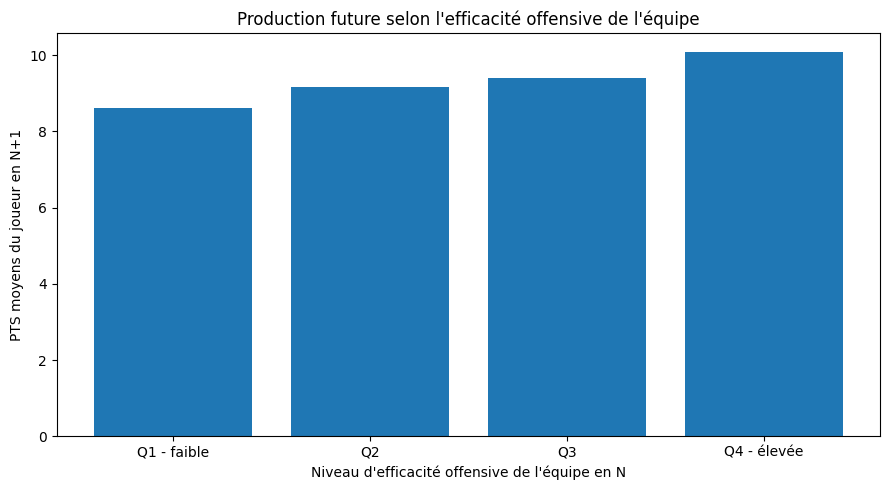

In [269]:
# Production future selon l'efficacité offensive de l'équipe

if "TEAM_OFF_RATING_GROUP" in team_eda_dataset.columns:

    plt.figure(
        figsize=(9, 5)
    )

    plt.bar(
        team_off_analysis[
            "TEAM_OFF_RATING_GROUP"
        ].astype(str),
        team_off_analysis[
            "pts_n1_moyen"
        ]
    )

    plt.xlabel(
        "Niveau d'efficacité offensive de l'équipe en N"
    )

    plt.ylabel(
        "PTS moyens du joueur en N+1"
    )

    plt.title(
        "Production future selon l'efficacité offensive de l'équipe"
    )

    plt.tight_layout()

    plt.show()

In [270]:
# Segmentation selon le pourcentage de victoires

if (
    "TEAM_W_PCT"
    in team_eda_dataset.columns
):

    team_eda_dataset[
        "TEAM_W_PCT_GROUP"
    ] = pd.qcut(
        team_eda_dataset[
            "TEAM_W_PCT"
        ],
        q=4,
        labels=[
            "Q1 - faible",
            "Q2",
            "Q3",
            "Q4 - élevé",
        ],
        duplicates="drop"
    )


    team_win_analysis = (
        team_eda_dataset
        .groupby(
            "TEAM_W_PCT_GROUP",
            observed=True
        )
        .agg(
            joueur_saisons=(
                "PLAYER_ID",
                "count"
            ),
            win_pct_moyen=(
                "TEAM_W_PCT",
                "mean"
            ),
            pts_n_moyen=(
                "PTS",
                "mean"
            ),
            pts_n1_moyen=(
                "pts_next_season",
                "mean"
            ),
            variation_moyenne=(
                "PTS_NEXT_CHANGE",
                "mean"
            ),
            variation_absolue_moyenne=(
                "ABS_PTS_NEXT_CHANGE",
                "mean"
            ),
        )
        .reset_index()
    )


    display(
        team_win_analysis.round(2)
    )

,TEAM_W_PCT_GROUP,joueur_saisons,win_pct_moyen,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_absolue_moyenne
0,Q1 - faible,2443,0.31,9.57,8.89,-0.69,2.72
1,Q2,1980,0.47,9.40,9.23,-0.17,2.53
2,Q3,2207,0.57,9.36,9.52,0.17,2.39
3,Q4 - élevé,2199,0.69,9.35,9.67,0.32,2.28


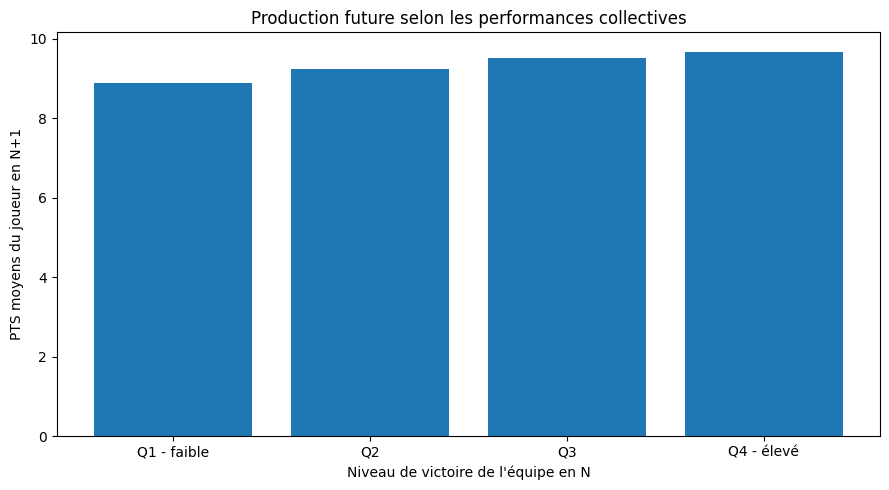

In [271]:
# Production future selon le pourcentage de victoires

if "TEAM_W_PCT_GROUP" in team_eda_dataset.columns:

    plt.figure(
        figsize=(9, 5)
    )

    plt.bar(
        team_win_analysis[
            "TEAM_W_PCT_GROUP"
        ].astype(str),
        team_win_analysis[
            "pts_n1_moyen"
        ]
    )

    plt.xlabel(
        "Niveau de victoire de l'équipe en N"
    )

    plt.ylabel(
        "PTS moyens du joueur en N+1"
    )

    plt.title(
        "Production future selon les performances collectives"
    )

    plt.tight_layout()

    plt.show()

In [272]:
# Segmentation selon le rythme de jeu

if (
    "TEAM_PACE"
    in team_eda_dataset.columns
):

    team_eda_dataset[
        "TEAM_PACE_GROUP"
    ] = pd.qcut(
        team_eda_dataset[
            "TEAM_PACE"
        ],
        q=4,
        labels=[
            "Q1 - lent",
            "Q2",
            "Q3",
            "Q4 - rapide",
        ],
        duplicates="drop"
    )


    team_pace_analysis = (
        team_eda_dataset
        .groupby(
            "TEAM_PACE_GROUP",
            observed=True
        )
        .agg(
            joueur_saisons=(
                "PLAYER_ID",
                "count"
            ),
            pace_moyen=(
                "TEAM_PACE",
                "mean"
            ),
            pts_n_moyen=(
                "PTS",
                "mean"
            ),
            pts_n1_moyen=(
                "pts_next_season",
                "mean"
            ),
            variation_moyenne=(
                "PTS_NEXT_CHANGE",
                "mean"
            ),
            variation_absolue_moyenne=(
                "ABS_PTS_NEXT_CHANGE",
                "mean"
            ),
        )
        .reset_index()
    )


    display(
        team_pace_analysis.round(2)
    )

,TEAM_PACE_GROUP,joueur_saisons,pace_moyen,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_absolue_moyenne
0,Q1 - lent,2215,90.01,8.84,8.77,-0.06,2.38
1,Q2,2208,92.70,9.28,9.02,-0.26,2.38
2,Q3,2208,95.40,9.59,9.47,-0.12,2.49
3,Q4 - rapide,2198,99.70,9.99,10.01,0.02,2.69


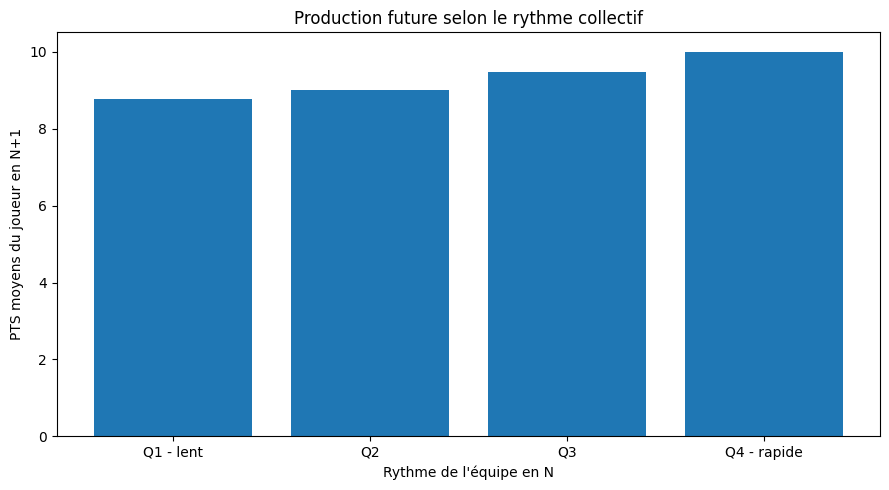

In [273]:
# Production future selon le rythme de jeu

if "TEAM_PACE_GROUP" in team_eda_dataset.columns:

    plt.figure(
        figsize=(9, 5)
    )

    plt.bar(
        team_pace_analysis[
            "TEAM_PACE_GROUP"
        ].astype(str),
        team_pace_analysis[
            "pts_n1_moyen"
        ]
    )

    plt.xlabel(
        "Rythme de l'équipe en N"
    )

    plt.ylabel(
        "PTS moyens du joueur en N+1"
    )

    plt.title(
        "Production future selon le rythme collectif"
    )

    plt.tight_layout()

    plt.show()

In [274]:
# Variable équipe la plus associée à la cible

best_team_feature = (
    team_correlations
    .assign(
        abs_corr=lambda df:
            df[
                "pearson_cible"
            ].abs()
    )
    .sort_values(
        "abs_corr",
        ascending=False
    )
    .iloc[0][
        "feature"
    ]
)


print(
    "Variable équipe la plus corrélée à la cible :",
    best_team_feature
)

Variable équipe la plus corrélée à la cible : TEAM_OFF_RATING


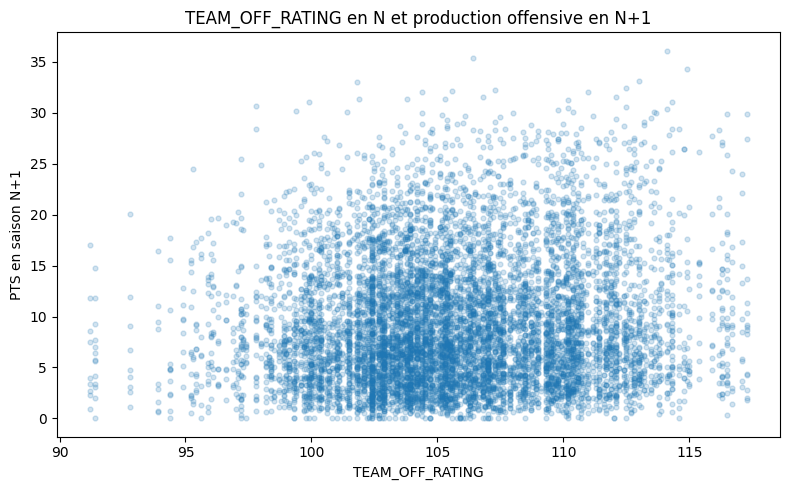

In [275]:
# Relation entre le meilleur signal équipe et la cible

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    team_eda_dataset[
        best_team_feature
    ],
    team_eda_dataset[
        "pts_next_season"
    ],
    alpha=0.2,
    s=12
)

plt.xlabel(
    best_team_feature
)

plt.ylabel(
    "PTS en saison N+1"
)

plt.title(
    f"{best_team_feature} en N et production offensive en N+1"
)

plt.tight_layout()

plt.show()

In [276]:
from scipy.stats import kruskal


team_test_rows = []


group_variables = {
    "TEAM_OFF_RATING":
        "TEAM_OFF_RATING_GROUP",

    "TEAM_W_PCT":
        "TEAM_W_PCT_GROUP",

    "TEAM_PACE":
        "TEAM_PACE_GROUP",
}


for feature, group_col in group_variables.items():

    if group_col not in team_eda_dataset.columns:
        continue


    samples = [
        group[
            "pts_next_season"
        ].dropna()
        for _, group
        in team_eda_dataset.groupby(
            group_col,
            observed=True
        )
    ]


    test = kruskal(
        *samples
    )


    team_test_rows.append({
        "variable": feature,
        "statistique": test.statistic,
        "p_value": test.pvalue,
    })


team_tests = pd.DataFrame(
    team_test_rows
)


team_tests[
    "significatif_5pct"
] = (
    team_tests[
        "p_value"
    ] < 0.05
)


display(
    team_tests
)

,variable,statistique,p_value,significatif_5pct
0,TEAM_OFF_RATING,41.831594,4.356223e-09,True
1,TEAM_W_PCT,12.710827,5.305582e-03,True
2,TEAM_PACE,40.435369,8.615087e-09,True


In [277]:
# Sauvegarde des résultats de la question 4

team_correlations.to_csv(
    REPORT_DIR
    / "Q4_correlations_contexte_equipe.csv",
    index=False,
    encoding="utf-8"
)


team_tests.to_csv(
    REPORT_DIR
    / "Q4_tests_contexte_equipe.csv",
    index=False,
    encoding="utf-8"
)


if "team_off_analysis" in globals():

    team_off_analysis.to_csv(
        REPORT_DIR
        / "Q4_analyse_off_rating.csv",
        index=False,
        encoding="utf-8"
    )


if "team_win_analysis" in globals():

    team_win_analysis.to_csv(
        REPORT_DIR
        / "Q4_analyse_win_pct.csv",
        index=False,
        encoding="utf-8"
    )


if "team_pace_analysis" in globals():

    team_pace_analysis.to_csv(
        REPORT_DIR
        / "Q4_analyse_pace.csv",
        index=False,
        encoding="utf-8"
    )

### Résultats

L'analyse principale porte sur **8 829 joueur-saisons mono-équipe**, soit
**89,08 %** des 9 911 observations supervisées. Les 1 082 saisons durant
lesquelles un joueur a évolué dans plusieurs équipes ont été exclues afin
d'éviter d'associer ses statistiques annuelles à une seule équipe de manière
ambiguë.

#### Corrélations avec les points en N+1

Les variables collectives présentent toutes des corrélations faibles avec
`pts_next_season` :

- `TEAM_OFF_RATING` : Pearson = **0,094**, Spearman = **0,074** ;
- `TEAM_PACE` : Pearson = **0,077**, Spearman = **0,067** ;
- `TEAM_W_PCT` : Pearson = **0,049**, Spearman = **0,032** ;
- `TEAM_NET_RATING` : Pearson = **0,048**, Spearman = **0,031** ;
- `TEAM_DEF_RATING` : Pearson = **0,043**, Spearman = **0,043**.

La variable la plus associée à la cible est donc `TEAM_OFF_RATING`, mais avec
un coefficient de Pearson de seulement **0,094**. La relation linéaire reste
donc très faible.

Le nuage de points confirme ce résultat : pour un même niveau d'efficacité
offensive collective, les niveaux de production individuelle en N+1 sont très
dispersés.

#### Efficacité offensive de l'équipe

Une légère progression apparaît néanmoins lorsque les équipes sont regroupées
par quartile d'efficacité offensive :

- quartile le plus faible : **8,63 PTS** en moyenne en N+1 ;
- Q2 : **9,18 PTS** ;
- Q3 : **9,41 PTS** ;
- quartile le plus élevé : **10,08 PTS**.

L'écart entre les deux quartiles extrêmes est donc de **1,45 point par match**,
soit environ **16,8 %** par rapport au groupe le plus faible.

La variation moyenne entre N et N+1 passe également de **-0,43 PTS** dans le
quartile offensif le plus faible à **+0,23 PTS** dans le quartile le plus élevé.

#### Pourcentage de victoires

La production future augmente également légèrement avec le niveau de victoire
de l'équipe :

- quartile le plus faible : **8,89 PTS** en N+1 ;
- Q2 : **9,23 PTS** ;
- Q3 : **9,52 PTS** ;
- quartile le plus élevé : **9,67 PTS**.

L'écart entre les deux groupes extrêmes est de seulement **0,78 point**.

La variation moyenne passe cependant de **-0,69 PTS** dans les équipes ayant
le plus faible pourcentage de victoires à **+0,32 PTS** dans les équipes du
quartile supérieur.

#### Rythme de jeu

Le rythme collectif montre également une différence descriptive :

- équipes les plus lentes : **8,77 PTS** en moyenne en N+1 ;
- Q2 : **9,02 PTS** ;
- Q3 : **9,47 PTS** ;
- équipes les plus rapides : **10,01 PTS**.

L'écart entre les deux quartiles extrêmes atteint **1,24 point**, soit environ
**14,1 %**.

Cependant, la corrélation entre `TEAM_PACE` et `pts_next_season` reste très
faible avec Pearson = **0,077**.

### Insight

Le contexte collectif de l'équipe en saison N est associé à certaines
différences de production offensive future, mais son pouvoir explicatif direct
semble limité.

Les joueurs appartenant aux équipes les plus efficaces offensivement, les plus
rapides ou les plus performantes collectivement affichent en moyenne une
production légèrement supérieure en N+1.

Cependant, les corrélations individuelles restent toutes inférieures à **0,10**
avec la cible. Le contexte d'équipe apparaît donc beaucoup moins informatif que
le rôle individuel étudié dans la Question 3.

À titre de comparaison :

- `FGA` : Pearson = **0,838** avec la cible ;
- `MIN` : Pearson = **0,718** ;
- `USG_PCT` : Pearson = **0,668** ;
- meilleure variable équipe, `TEAM_OFF_RATING` : Pearson = seulement **0,094**.

Le niveau futur d'un joueur semble donc dépendre beaucoup plus fortement de son
propre rôle offensif que du niveau global de son équipe.

### Recommandation

Les variables d'équipe peuvent être conservées comme informations
complémentaires dans le futur modèle, mais elles ne devraient pas être
considérées comme les principaux signaux prédictifs.

La priorité devrait être donnée aux variables individuelles :

- production actuelle ;
- volume de tirs ;
- temps de jeu ;
- usage offensif ;
- âge et expérience ;
- historique du joueur.

Les variables collectives pourront ensuite permettre au modèle d'apporter un
ajustement lié au contexte dans lequel évolue le joueur.

Il sera intéressant de vérifier lors de la modélisation si ces variables
d'équipe améliorent réellement les performances une fois les informations
individuelles déjà prises en compte.

### Confiance et limites

**Niveau de confiance : élevé pour le constat que les associations directes
sont faibles, moyen pour l'effet réel du contexte collectif.**

Les résultats reposent sur 8 829 observations et les différentes analyses
donnent une conclusion cohérente : les différences existent mais restent
nettement plus faibles que celles observées pour les variables individuelles.

Les tests de Kruskal-Wallis donnent des p-values inférieures à 0,05 pour
`TEAM_OFF_RATING`, `TEAM_W_PCT` et `TEAM_PACE`. Ces résultats indiquent que les
distributions diffèrent entre les quartiles.

Cependant, la significativité statistique ne doit pas être confondue avec
l'importance de l'effet. Avec un grand nombre d'observations, de faibles
différences peuvent devenir statistiquement significatives alors que les
corrélations restent très faibles.

De plus, une même valeur de contexte collectif est partagée par plusieurs
joueurs appartenant à la même équipe et à la même saison. Les observations ne
sont donc pas totalement indépendantes du point de vue du contexte d'équipe.
Les p-values doivent pour cette raison être interprétées avec prudence.

Enfin, l'analyse exclut **1 082 joueur-saisons multi-équipe**, soit **10,92 %**
du dataset supervisé. Les résultats concernent donc principalement les joueurs
ayant évolué dans une seule équipe pendant la saison.

## Question Business 5 : poste, profil offensif et performance future

### Reformulation

**Question précise :**  
Le poste principal d'un joueur est-il associé à son profil offensif en saison N
et à son niveau de production en saison N+1 ?

**Dimensions étudiées :**
- temps de jeu ;
- volume de tirs ;
- usage offensif ;
- passes décisives ;
- rebonds ;
- part de tirs à trois points ;
- efficacité au tir ;
- points en saison N ;
- points en saison N+1 ;
- évolution entre N et N+1.

**Granularité :**  
une ligne par joueur-saison disposant d'une saison N+1 consécutive.

La variable `POSITION` provient du roster. Les observations sans position
disponible sont exclues uniquement de cette analyse.

Les postes hybrides sont regroupés selon le premier poste indiqué afin
d'obtenir trois groupes principaux : Guard, Forward et Center.

In [278]:
# Disponibilité des positions

position_available = (
    eda_dataset[
        "POSITION"
    ]
    .notna()
    .sum()
)


print(
    "Observations totales :",
    len(eda_dataset)
)

print(
    "Position disponible :",
    position_available
)

print(
    "Position manquante :",
    len(eda_dataset)
    - position_available
)

print(
    "Couverture (%) :",
    round(
        position_available
        / len(eda_dataset)
        * 100,
        2
    )
)

Observations totales : 9911
Position disponible : 9406
Position manquante : 505
Couverture (%) : 94.9


In [279]:
# Distribution des positions brutes

position_raw_distribution = (
    eda_dataset[
        "POSITION"
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "position"
    )
    .reset_index(
        name="joueur_saisons"
    )
)


position_raw_distribution[
    "pourcentage"
] = (
    position_raw_distribution[
        "joueur_saisons"
    ]
    / len(eda_dataset)
    * 100
).round(2)


display(
    position_raw_distribution
)

,position,joueur_saisons,pourcentage
0,G,3290,33.20
1,F,2863,28.89
2,C,1195,12.06
3,G-F,634,6.40
4,F-C,566,5.71
5,None,505,5.10
6,C-F,462,4.66
7,F-G,396,4.00


In [280]:
# Regroupement des postes

position_dataset = (
    eda_dataset[
        eda_dataset[
            "POSITION"
        ].notna()
    ]
    .copy()
)


position_dataset[
    "POSITION_PRIMARY"
] = (
    position_dataset[
        "POSITION"
    ]
    .astype("string")
    .str.strip()
    .str[0]
    .map({
        "G": "Guard",
        "F": "Forward",
        "C": "Center",
    })
)


position_dataset = (
    position_dataset[
        position_dataset[
            "POSITION_PRIMARY"
        ].notna()
    ]
    .copy()
)


position_order = [
    "Guard",
    "Forward",
    "Center",
]


primary_position_distribution = (
    position_dataset[
        "POSITION_PRIMARY"
    ]
    .value_counts()
    .reindex(
        position_order
    )
    .rename_axis(
        "poste"
    )
    .reset_index(
        name="joueur_saisons"
    )
)


primary_position_distribution[
    "pourcentage"
] = (
    primary_position_distribution[
        "joueur_saisons"
    ]
    / len(position_dataset)
    * 100
).round(2)


display(
    primary_position_distribution
)

,poste,joueur_saisons,pourcentage
0,Guard,3924,41.72
1,Forward,3825,40.67
2,Center,1657,17.62


In [281]:
# Préparation de l'usage en pourcentage

if (
    "USG_PERCENT"
    not in position_dataset.columns
):

    if (
        position_dataset[
            "USG_PCT"
        ].median()
        <= 1
    ):

        position_dataset[
            "USG_PERCENT"
        ] = (
            position_dataset[
                "USG_PCT"
            ]
            * 100
        )

    else:

        position_dataset[
            "USG_PERCENT"
        ] = (
            position_dataset[
                "USG_PCT"
            ]
        )

In [282]:
# Profil moyen par poste

position_profile = (
    position_dataset
    .groupby(
        "POSITION_PRIMARY"
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        age_moyen=(
            "AGE",
            "mean"
        ),
        minutes=(
            "MIN",
            "mean"
        ),
        tirs=(
            "FGA",
            "mean"
        ),
        usage=(
            "USG_PERCENT",
            "mean"
        ),
        passes=(
            "AST",
            "mean"
        ),
        rebonds=(
            "REB",
            "mean"
        ),
        part_tirs_3pts=(
            "FG3A_RATE",
            "mean"
        ),
        efficacite=(
            "TS_PCT",
            "mean"
        ),
        pts_n=(
            "PTS",
            "mean"
        ),
        pts_n1=(
            "pts_next_season",
            "mean"
        ),
        evolution=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
    )
    .reindex(
        position_order
    )
    .reset_index()
)


display(
    position_profile.round(3)
)

,POSITION_PRIMARY,joueur_saisons,age_moyen,minutes,tirs,usage,passes,rebonds,part_tirs_3pts,efficacite,pts_n,pts_n1,evolution
0,Guard,3924,26.710,23.708,8.563,19.449,3.076,2.718,0.345,0.522,10.162,10.081,-0.081
1,Forward,3825,26.695,22.641,7.682,18.303,1.492,4.637,0.225,0.531,9.404,9.224,-0.179
2,Center,1657,27.253,20.513,6.165,17.161,1.028,5.748,0.042,0.540,7.917,7.568,-0.349


In [283]:
# Production offensive par poste

position_future = (
    position_dataset
    .groupby(
        "POSITION_PRIMARY"
    )
    .agg(
        joueur_saisons=(
            "PLAYER_ID",
            "count"
        ),
        pts_n_moyen=(
            "PTS",
            "mean"
        ),
        pts_n1_moyen=(
            "pts_next_season",
            "mean"
        ),
        variation_moyenne=(
            "PTS_NEXT_CHANGE",
            "mean"
        ),
        variation_mediane=(
            "PTS_NEXT_CHANGE",
            "median"
        ),
        variation_absolue_moyenne=(
            "ABS_PTS_NEXT_CHANGE",
            "mean"
        ),
    )
    .reindex(
        position_order
    )
    .reset_index()
)


display(
    position_future.round(2)
)

,POSITION_PRIMARY,joueur_saisons,pts_n_moyen,pts_n1_moyen,variation_moyenne,variation_mediane,variation_absolue_moyenne
0,Guard,3924,10.16,10.08,-0.08,-0.2,2.62
1,Forward,3825,9.40,9.22,-0.18,-0.3,2.43
2,Center,1657,7.92,7.57,-0.35,-0.4,2.13


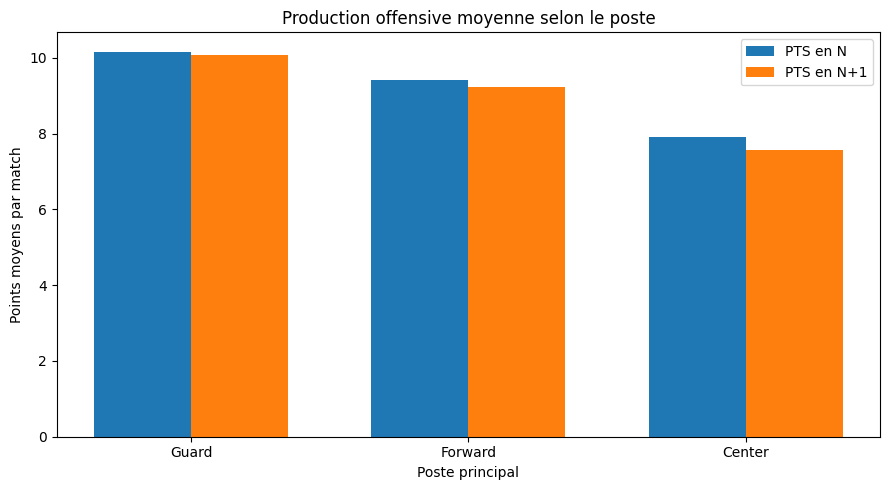

In [284]:
# Production actuelle et future par poste

x = np.arange(
    len(position_future)
)

width = 0.35


plt.figure(
    figsize=(9, 5)
)

plt.bar(
    x - width / 2,
    position_future[
        "pts_n_moyen"
    ],
    width,
    label="PTS en N"
)

plt.bar(
    x + width / 2,
    position_future[
        "pts_n1_moyen"
    ],
    width,
    label="PTS en N+1"
)

plt.xticks(
    x,
    position_future[
        "POSITION_PRIMARY"
    ]
)

plt.ylabel(
    "Points moyens par match"
)

plt.xlabel(
    "Poste principal"
)

plt.title(
    "Production offensive moyenne selon le poste"
)

plt.legend()

plt.tight_layout()

plt.show()

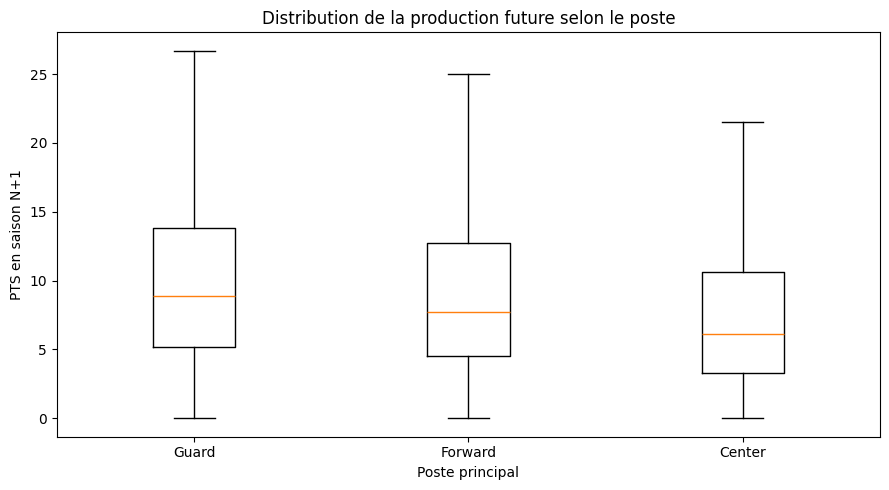

In [285]:
# Distribution des points en N+1 selon le poste

position_target_samples = [
    position_dataset.loc[
        position_dataset[
            "POSITION_PRIMARY"
        ] == position,
        "pts_next_season"
    ].dropna()
    for position in position_order
]


plt.figure(
    figsize=(9, 5)
)

plt.boxplot(
    position_target_samples,
    tick_labels=position_order,
    showfliers=False
)

plt.xlabel(
    "Poste principal"
)

plt.ylabel(
    "PTS en saison N+1"
)

plt.title(
    "Distribution de la production future selon le poste"
)

plt.tight_layout()

plt.show()

In [286]:
# Indice de profil relatif à la moyenne

profile_features = [
    "minutes",
    "tirs",
    "usage",
    "passes",
    "rebonds",
    "part_tirs_3pts",
    "efficacite",
]


overall_profile = {
    "minutes":
        position_dataset["MIN"].mean(),

    "tirs":
        position_dataset["FGA"].mean(),

    "usage":
        position_dataset["USG_PERCENT"].mean(),

    "passes":
        position_dataset["AST"].mean(),

    "rebonds":
        position_dataset["REB"].mean(),

    "part_tirs_3pts":
        position_dataset[
            "FG3A_RATE"
        ].mean(),

    "efficacite":
        position_dataset[
            "TS_PCT"
        ].mean(),
}


position_profile_index = (
    position_profile[
        [
            "POSITION_PRIMARY"
        ]
        + profile_features
    ]
    .copy()
)


for feature in profile_features:

    position_profile_index[
        feature
    ] = (
        position_profile_index[
            feature
        ]
        / overall_profile[
            feature
        ]
        * 100
    )


display(
    position_profile_index.round(1)
)

,POSITION_PRIMARY,minutes,tirs,usage,passes,rebonds,part_tirs_3pts,efficacite
0,Guard,104.4,110.0,104.7,148.5,67.4,142.1,98.7
1,Forward,99.7,98.7,98.5,72.0,115.0,92.6,100.4
2,Center,90.3,79.2,92.4,49.6,142.6,17.3,102.1


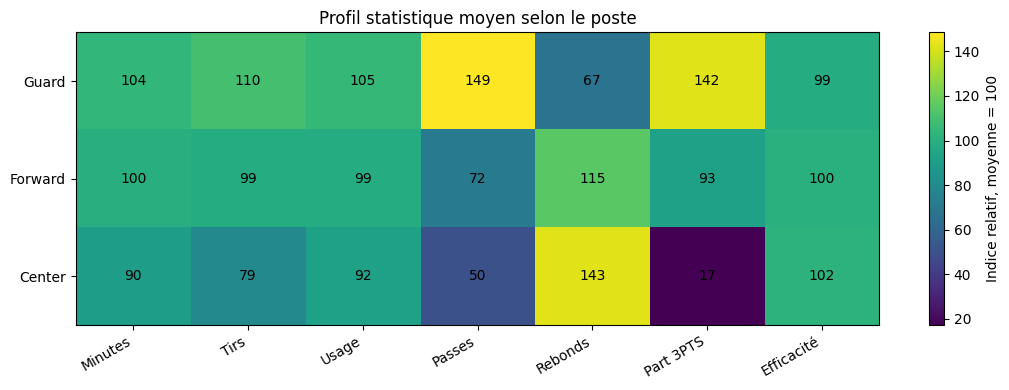

In [287]:
# Heatmap du profil offensif

heatmap_data = (
    position_profile_index[
        profile_features
    ]
    .to_numpy()
)


fig, ax = plt.subplots(
    figsize=(11, 4)
)


image = ax.imshow(
    heatmap_data,
    aspect="auto"
)


ax.set_xticks(
    np.arange(
        len(profile_features)
    )
)

ax.set_xticklabels(
    [
        "Minutes",
        "Tirs",
        "Usage",
        "Passes",
        "Rebonds",
        "Part 3PTS",
        "Efficacité",
    ],
    rotation=30,
    ha="right"
)


ax.set_yticks(
    np.arange(
        len(position_order)
    )
)

ax.set_yticklabels(
    position_order
)


for i in range(
    len(position_order)
):

    for j in range(
        len(profile_features)
    ):

        ax.text(
            j,
            i,
            f"{heatmap_data[i, j]:.0f}",
            ha="center",
            va="center"
        )


plt.colorbar(
    image,
    label="Indice relatif, moyenne = 100"
)

plt.title(
    "Profil statistique moyen selon le poste"
)

plt.tight_layout()

plt.show()

In [288]:
from scipy.stats import kruskal


# Différences de production future entre postes

position_target_test = kruskal(
    *position_target_samples
)


position_change_samples = [
    position_dataset.loc[
        position_dataset[
            "POSITION_PRIMARY"
        ] == position,
        "PTS_NEXT_CHANGE"
    ].dropna()
    for position in position_order
]


position_change_test = kruskal(
    *position_change_samples
)


position_tests = pd.DataFrame([
    {
        "analyse":
            "PTS en N+1 selon le poste",
        "test":
            "Kruskal-Wallis",
        "statistique":
            position_target_test.statistic,
        "p_value":
            position_target_test.pvalue,
    },
    {
        "analyse":
            "Evolution N vers N+1 selon le poste",
        "test":
            "Kruskal-Wallis",
        "statistique":
            position_change_test.statistic,
        "p_value":
            position_change_test.pvalue,
    },
])


position_tests[
    "significatif_5pct"
] = (
    position_tests[
        "p_value"
    ] < 0.05
)


display(
    position_tests
)

,analyse,test,statistique,p_value,significatif_5pct
0,PTS en N+1 selon le poste,Kruskal-Wallis,229.052793,1.827335e-50,True
1,Evolution N vers N+1 selon le poste,Kruskal-Wallis,4.693002,9.570344e-02,False


In [289]:
# Taille d'effet du test de Kruskal-Wallis

def kruskal_epsilon_squared(
    statistic,
    n,
    k
):

    value = (
        statistic
        - k
        + 1
    ) / (
        n
        - k
    )

    return max(
        0,
        value
    )


target_effect_size = (
    kruskal_epsilon_squared(
        position_target_test.statistic,
        sum(
            len(sample)
            for sample
            in position_target_samples
        ),
        len(
            position_target_samples
        )
    )
)


change_effect_size = (
    kruskal_epsilon_squared(
        position_change_test.statistic,
        sum(
            len(sample)
            for sample
            in position_change_samples
        ),
        len(
            position_change_samples
        )
    )
)


position_effect_sizes = pd.DataFrame([
    {
        "analyse":
            "PTS en N+1 selon le poste",
        "epsilon_squared":
            target_effect_size,
    },
    {
        "analyse":
            "Evolution selon le poste",
        "epsilon_squared":
            change_effect_size,
    },
])


display(
    position_effect_sizes.round(4)
)

,analyse,epsilon_squared
0,PTS en N+1 selon le poste,0.0241
1,Evolution selon le poste,0.0003


In [290]:
from itertools import combinations

from scipy.stats import mannwhitneyu


# Comparaisons deux à deux

pairwise_rows = []


position_pairs = list(
    combinations(
        position_order,
        2
    )
)


for position_a, position_b in position_pairs:

    sample_a = position_dataset.loc[
        position_dataset[
            "POSITION_PRIMARY"
        ] == position_a,
        "pts_next_season"
    ].dropna()


    sample_b = position_dataset.loc[
        position_dataset[
            "POSITION_PRIMARY"
        ] == position_b,
        "pts_next_season"
    ].dropna()


    result = mannwhitneyu(
        sample_a,
        sample_b,
        alternative="two-sided"
    )


    pairwise_rows.append({
        "poste_1": position_a,
        "poste_2": position_b,
        "mediane_1":
            sample_a.median(),
        "mediane_2":
            sample_b.median(),
        "p_value":
            result.pvalue,
    })


position_pairwise = pd.DataFrame(
    pairwise_rows
)


position_pairwise[
    "p_value_bonferroni"
] = np.minimum(
    position_pairwise[
        "p_value"
    ]
    * len(
        position_pairs
    ),
    1
)


position_pairwise[
    "significatif_5pct"
] = (
    position_pairwise[
        "p_value_bonferroni"
    ] < 0.05
)


display(
    position_pairwise.round(4)
)

,poste_1,poste_2,mediane_1,mediane_2,p_value,p_value_bonferroni,significatif_5pct
0,Guard,Forward,8.9,7.7,0.0,0.0,True
1,Guard,Center,8.9,6.1,0.0,0.0,True
2,Forward,Center,7.7,6.1,0.0,0.0,True


In [291]:
# Sauvegarde des résultats de la question 5

position_raw_distribution.to_csv(
    REPORT_DIR
    / "Q5_positions_brutes.csv",
    index=False,
    encoding="utf-8"
)


primary_position_distribution.to_csv(
    REPORT_DIR
    / "Q5_distribution_postes.csv",
    index=False,
    encoding="utf-8"
)


position_profile.to_csv(
    REPORT_DIR
    / "Q5_profils_postes.csv",
    index=False,
    encoding="utf-8"
)


position_future.to_csv(
    REPORT_DIR
    / "Q5_production_future_postes.csv",
    index=False,
    encoding="utf-8"
)


position_tests.to_csv(
    REPORT_DIR
    / "Q5_tests_postes.csv",
    index=False,
    encoding="utf-8"
)


position_effect_sizes.to_csv(
    REPORT_DIR
    / "Q5_taille_effet_postes.csv",
    index=False,
    encoding="utf-8"
)


position_pairwise.to_csv(
    REPORT_DIR
    / "Q5_comparaisons_postes.csv",
    index=False,
    encoding="utf-8"
)

### Résultats

L'analyse porte sur **9 406 joueur-saisons disposant d'une position connue**,
soit **94,9 %** des 9 911 observations du dataset supervisé.

Après regroupement des positions hybrides selon leur poste principal, la
répartition est la suivante :

- Guards : **3 924 observations**, soit **41,72 %** ;
- Forwards : **3 825 observations**, soit **40,67 %** ;
- Centers : **1 657 observations**, soit **17,62 %**.

### Des profils offensifs nettement différents

Les statistiques moyennes montrent des profils très différents selon le poste.

#### Guards

Les Guards présentent le profil le plus orienté vers la création et le jeu
extérieur :

- **3,08 passes décisives** par match, soit environ **49 % au-dessus de la
  moyenne générale** ;
- **34,5 %** de leurs tentatives de tir sont des tirs à trois points ;
- leur indice relatif de tirs à trois points atteint **142**, pour une moyenne
  générale fixée à 100 ;
- ils tentent en moyenne **8,56 tirs** par match ;
- leur usage moyen est de **19,45 %**.

Ils possèdent également la production offensive moyenne la plus élevée avec
**10,16 PTS en N** et **10,08 PTS en N+1**.

#### Forwards

Les Forwards présentent un profil plus équilibré :

- **7,68 tirs** par match ;
- usage moyen de **18,30 %** ;
- **1,49 passe décisive** ;
- **4,64 rebonds** ;
- part de tirs à trois points de **22,5 %**.

Leur production moyenne atteint **9,40 PTS en N** puis **9,22 PTS en N+1**.

#### Centers

Les Centers présentent un profil très différent :

- seulement **6,17 tirs** par match ;
- usage moyen de **17,16 %** ;
- **1,03 passe décisive** ;
- **5,75 rebonds**, soit environ **43 % au-dessus de la moyenne générale** ;
- seulement **4,2 %** de leurs tentatives sont des tirs à trois points.

Ils affichent cependant la meilleure efficacité moyenne au tir parmi les trois
groupes avec un `TS_PCT` de **0,540**, contre **0,531** chez les Forwards et
**0,522** chez les Guards.

Leur volume offensif plus faible se traduit par une production moyenne de
**7,92 PTS en N** et **7,57 PTS en N+1**.

### Poste et niveau de production en N+1

La production moyenne en N+1 diffère selon le poste :

- Guards : **10,08 PTS** ;
- Forwards : **9,22 PTS** ;
- Centers : **7,57 PTS**.

Les médianes suivent la même hiérarchie :

- Guards : **8,9 PTS** ;
- Forwards : **7,7 PTS** ;
- Centers : **6,1 PTS**.

Le test de Kruskal-Wallis indique que les distributions de points en N+1
diffèrent statistiquement entre les postes
(`p < 0,001`).

Les comparaisons deux à deux restent également significatives après correction
de Bonferroni entre :

- Guards et Forwards ;
- Guards et Centers ;
- Forwards et Centers.

Cependant, la taille d'effet mesurée par epsilon carré est seulement de
**0,0241**.

Le poste est donc associé au niveau de scoring futur, mais son effet reste
**faible** lorsqu'il est considéré seul.

### Poste et évolution entre N et N+1

Les variations moyennes sont faibles pour les trois groupes :

- Guards : **-0,08 PTS** ;
- Forwards : **-0,18 PTS** ;
- Centers : **-0,35 PTS**.

Le test de Kruskal-Wallis sur l'évolution entre N et N+1 donne une
p-value d'environ **0,096**, supérieure au seuil de 5 %.

La différence d'évolution entre les postes n'est donc pas statistiquement
significative.

La taille d'effet est également quasiment nulle avec un epsilon carré de
**0,0003**.

### Insight

Le poste permet surtout de caractériser **la manière dont un joueur produit ses
statistiques**, plutôt que d'anticiper sa progression future.

Les Guards se distinguent par la création, le volume de tirs et les tirs à
trois points, tandis que les Centers se distinguent principalement par les
rebonds, une meilleure efficacité au tir et un jeu beaucoup moins orienté vers
le tir extérieur. Les Forwards présentent un profil intermédiaire.

Le poste est également associé au niveau moyen de points en N+1, avec une
hiérarchie Guards, Forwards, Centers.

Cependant, l'effet statistique du poste sur la cible reste faible
(`epsilon² = 0,0241`) et aucune différence significative n'est observée dans
l'évolution des points entre N et N+1.

Le poste semble donc utile pour contextualiser le profil du joueur, mais il ne
suffit pas à expliquer pourquoi un joueur progressera ou régressera lors de la
saison suivante.

### Recommandation

La position peut être conservée comme variable catégorielle candidate pour le
futur modèle, car elle apporte une information complémentaire sur le profil du
joueur.

Elle devra cependant être utilisée avec les variables individuelles plus
directement liées à la production offensive, notamment :

- volume de tirs ;
- temps de jeu ;
- usage ;
- âge et expérience ;
- production actuelle et historique.

Il pourra également être intéressant pour le modèle d'apprendre des interactions
entre le poste et certaines statistiques. Par exemple, un même niveau de rebonds,
de tirs à trois points ou de passes n'a pas nécessairement la même signification
pour un Guard que pour un Center.

### Confiance et limites

**Niveau de confiance : élevé pour les différences de profil entre postes,
moyen pour leur importance prédictive.**

Les profils observés sont cohérents et reposent sur plusieurs milliers
d'observations.

Cependant, la taille d'effet du poste sur `pts_next_season` reste faible malgré
une forte significativité statistique. Avec un échantillon important, de petites
différences peuvent produire des p-values très faibles.

La position est également une représentation simplifiée du rôle réel du joueur.
Un Guard peut être principalement scoreur ou créateur, tandis qu'un Center peut
avoir un profil intérieur ou plus polyvalent.

Enfin, **505 observations** ne disposent pas de position et sont exclues de
cette analyse. Les positions hybrides ont également été regroupées selon le
premier poste indiqué, ce qui simplifie certains profils polyvalents.

## Synthèse des analyses

Les cinq questions business ont permis d'étudier successivement la stabilité
de la production offensive, l'effet de la phase de carrière, le rôle offensif
individuel, le contexte collectif et le poste du joueur.

Le tableau suivant synthétise les principaux résultats obtenus.

In [292]:
# Synthèse des cinq questions business

findings_summary = pd.DataFrame([
    {
        "question": "Q1 - Progression et régression",
        "insight_principal":
            "La production est relativement persistante, mais près d'une observation sur deux évolue d'au moins 2 PTS.",
        "chiffre_cle":
            "49,47 % avec |variation| >= 2 PTS",
        "confiance":
            "Élevée",
        "action":
            "Utiliser la production récente comme référence et chercher les facteurs expliquant les écarts."
    },
    {
        "question": "Q2 - Âge et expérience",
        "insight_principal":
            "Les jeunes joueurs progressent plus souvent tandis que la régression devient dominante avec l'âge et l'expérience.",
        "chiffre_cle":
            "40,81 % de progression chez les <= 22 ans contre 7,31 % chez les 32+",
        "confiance":
            "Élevée",
        "action":
            "Intégrer l'âge et l'expérience avec une relation non linéaire."
    },
    {
        "question": "Q3 - Rôle offensif",
        "insight_principal":
            "Le rôle offensif en N est fortement associé au niveau de points en N+1, surtout le volume de tirs.",
        "chiffre_cle":
            "FGA : Pearson = 0,838 avec pts_next_season",
        "confiance":
            "Élevée",
        "action":
            "Prioriser FGA, MIN, USG_PCT et les variables historiques dans la modélisation."
    },
    {
        "question": "Q4 - Contexte collectif",
        "insight_principal":
            "Le contexte de l'équipe apporte un signal beaucoup plus faible que les caractéristiques individuelles.",
        "chiffre_cle":
            "Meilleure corrélation équipe : TEAM_OFF_RATING = 0,094",
        "confiance":
            "Élevée",
        "action":
            "Conserver les variables équipe comme informations complémentaires."
    },
    {
        "question": "Q5 - Poste du joueur",
        "insight_principal":
            "Le poste caractérise fortement le profil statistique mais explique peu à lui seul la production future.",
        "chiffre_cle":
            "Effet du poste sur N+1 : epsilon² = 0,0241",
        "confiance":
            "Élevée sur les profils, moyenne sur la valeur prédictive",
        "action":
            "Conserver POSITION et tester ses interactions avec les statistiques individuelles."
    }
])


display(
    findings_summary
)

,question,insight_principal,chiffre_cle,confiance,action
0,Q1 - Progression et régression,"La production est relativement persistante, ma...","49,47 % avec |variation| >= 2 PTS",Élevée,Utiliser la production récente comme référence...
1,Q2 - Âge et expérience,Les jeunes joueurs progressent plus souvent ta...,"40,81 % de progression chez les <= 22 ans cont...",Élevée,Intégrer l'âge et l'expérience avec une relati...
2,Q3 - Rôle offensif,Le rôle offensif en N est fortement associé au...,"FGA : Pearson = 0,838 avec pts_next_season",Élevée,"Prioriser FGA, MIN, USG_PCT et les variables h..."
3,Q4 - Contexte collectif,Le contexte de l'équipe apporte un signal beau...,Meilleure corrélation équipe : TEAM_OFF_RATING...,Élevée,Conserver les variables équipe comme informati...
4,Q5 - Poste du joueur,Le poste caractérise fortement le profil stati...,"Effet du poste sur N+1 : epsilon² = 0,0241","Élevée sur les profils, moyenne sur la valeur ...",Conserver POSITION et tester ses interactions ...


In [293]:
# Sauvegarde de la synthèse

findings_summary.to_csv(
    REPORT_DIR
    / "00_synthese_questions_business.csv",
    index=False,
    encoding="utf-8"
)

## Findings inattendus

### 1. Les performances collectives sont statistiquement significatives mais peu informatives

Les différences entre groupes d'équipes sont parfois statistiquement
significatives, mais les corrélations avec `pts_next_season` restent très
faibles.

Par exemple, `TEAM_OFF_RATING`, meilleure variable collective étudiée,
n'obtient qu'une corrélation de **0,094** avec la cible, alors que `FGA`
atteint **0,838**.

Cela montre qu'une significativité statistique ne signifie pas nécessairement
qu'une variable possède un fort intérêt prédictif.

### 2. Un rôle offensif important annonce surtout un niveau futur élevé, pas une progression

Les joueurs ayant beaucoup de tirs, de minutes ou d'usage en saison N
conservent généralement une production élevée en N+1.

En revanche, ces variables sont faiblement et négativement associées à
`PTS_NEXT_CHANGE`.

Ainsi, un joueur déjà très impliqué offensivement dispose généralement de moins
de marge de progression supplémentaire.

### 3. Le poste décrit mieux le profil du joueur que son évolution future

Les Guards, Forwards et Centers présentent des profils statistiques très
différents, notamment sur les passes, les rebonds et les tirs à trois points.

Cependant, le poste n'est pas significativement associé à l'évolution entre
N et N+1 et sa taille d'effet sur le niveau de points futur reste faible
(`epsilon² = 0,0241`).

Le poste semble donc surtout apporter du contexte au modèle plutôt qu'un signal
prédictif majeur lorsqu'il est utilisé seul.

## Recommandations priorisées

### Priorité 1 : exploiter la continuité de la production offensive

La production actuelle constitue le point de départ naturel de la prédiction.

Les variables `PTS`, les statistiques de la saison précédente et les moyennes
historiques devront servir de références principales pour anticiper
`pts_next_season`.

### Priorité 2 : intégrer le rôle offensif individuel

Le volume de tirs, le temps de jeu et l'usage présentent les associations les
plus importantes avec la production future.

`FGA` apparaît notamment comme l'un des signaux les plus prometteurs avec une
corrélation de **0,838** avec la cible.

### Priorité 3 : modéliser la phase de carrière de façon non linéaire

La relation entre âge, expérience et évolution offensive n'est pas linéaire.

Les jeunes joueurs progressent beaucoup plus fréquemment alors que la
régression devient dominante chez les joueurs plus âgés.

Les variables `AGE_GROUP` et `EXPERIENCE_GROUP` pourront aider à représenter
ces différentes phases de carrière.

### Priorité 4 : utiliser le contexte comme information complémentaire

Le contexte collectif et le poste apportent des informations utiles pour
caractériser le joueur, mais leur association directe avec la cible est
nettement plus faible.

Ils devront donc compléter les statistiques individuelles plutôt que les
remplacer.

### Priorité 5 : analyser les erreurs par profil après modélisation

Les performances du futur modèle devront être étudiées séparément selon :

- l'âge ;
- l'expérience ;
- le niveau de production ;
- le volume de tirs ;
- l'usage ;
- le poste.

Cette analyse permettra d'identifier les profils pour lesquels les prédictions
sont les moins fiables.

## Validation des conclusions

Les principaux résultats ont été vérifiés selon plusieurs critères.

### Fiabilité des données

Les analyses reposent principalement sur **9 911 joueur-saisons** possédant
une saison N+1 consécutive.

Certaines sous-analyses utilisent un échantillon légèrement réduit lorsque des
informations provenant du roster sont nécessaires :

- expérience ;
- position.

### Taille des groupes

Les groupes principaux contiennent généralement plusieurs centaines ou
plusieurs milliers d'observations.

Les résultats aux âges les plus élevés sont cependant moins robustes car les
effectifs deviennent faibles.

### Corrélation et causalité

Aucune corrélation observée n'est interprétée comme une preuve de causalité.

Par exemple, un grand nombre de tirs est fortement associé aux points futurs,
mais cela peut également refléter le fait que les meilleurs scoreurs reçoivent
déjà davantage de responsabilités offensives.

### Significativité et importance réelle

Les p-values sont interprétées conjointement avec les écarts observés,
les corrélations et, lorsque cela est pertinent, les tailles d'effet.

Cette distinction est notamment importante pour :

- les statistiques équipe ;
- le poste du joueur.

Ces variables peuvent présenter des différences statistiquement significatives
tout en ayant un effet pratique faible.

### Facteurs absents

Certaines évolutions importantes peuvent être liées à des informations qui ne
sont pas disponibles dans le dataset :

- blessures ;
- changements de rôle ;
- mouvements d'effectif ;
- nombre de matchs manqués ;
- contexte contractuel ou personnel.

Ces facteurs limitent la capacité à expliquer totalement les variations
individuelles.

### Limite liée à la définition de la cible

Le dataset supervisé contient uniquement les joueur-saisons pour lesquels une
saison N+1 consécutive est observée.

Les analyses décrivent donc la production future **conditionnellement au fait
que le joueur soit encore observé en NBA lors de la saison suivante**.

Les retraites, sorties de ligue ou saisons totalement manquées ne sont pas
représentées par `pts_next_season`.

Cette sélection devra être prise en compte lors de l'interprétation des
performances du futur modèle.

## Questions de réflexion

### 1. Quel résultat a été le plus surprenant ?

Le faible poids apparent du contexte collectif constitue l'un des résultats les
plus surprenants.

Même si les joueurs des meilleures équipes présentent certaines différences
moyennes, les variables collectives ont toutes des corrélations inférieures à
0,10 avec `pts_next_season`.

Les caractéristiques individuelles semblent donc largement dominer les
caractéristiques de l'équipe.

### 2. Quel insight semble avoir le plus d'impact ?

Le rôle offensif individuel semble être l'information la plus importante pour
anticiper le niveau futur de production.

Le volume de tirs `FGA` présente notamment une corrélation de **0,838** avec la
cible.

Ce résultat suggère que la responsabilité offensive actuelle du joueur devrait
constituer un élément central du futur modèle.

### 3. Quelles sont les principales limites ?

Les principales limites sont :

- absence d'informations détaillées sur les blessures ;
- absence de certains changements de rôle ou d'effectif ;
- impossibilité de modéliser les joueurs absents de N+1 ;
- dépendance entre certaines variables explicatives ;
- effectifs faibles pour certains profils rares ;
- position simplifiée pour les joueurs polyvalents.

Ces limites empêchent d'interpréter les associations observées comme des
relations causales.

### 4. Quelles analyses complémentaires auraient pu enrichir les conclusions ?

Des données supplémentaires permettraient notamment d'étudier :

- les blessures et matchs manqués ;
- les changements de titulaire ou de rôle ;
- les transferts entre N et N+1 ;
- les changements d'entraîneur ;
- la concurrence au sein du roster ;
- les contrats et mouvements d'effectif.

Ces variables pourraient aider à expliquer les variations importantes qui
restent difficiles à anticiper avec les statistiques disponibles.

## Utilisation de l'IA

L'IA a été intégrée au processus d'EDA analytique pour :

- proposer les méthodes adaptées à chaque question business ;
- identifier les variables pertinentes à comparer ;
- suggérer des segmentations interprétables ;
- aider à choisir les tests statistiques ;
- interpréter les résultats obtenus ;
- distinguer significativité statistique et importance réelle ;
- identifier les limites et explications alternatives ;
- reformuler les résultats sous forme d'insights actionnables.

Les conclusions n'ont pas été générées indépendamment des données.

Chaque interprétation a été formulée uniquement après exécution des analyses et
observation des résultats chiffrés.

## Conclusion de la Phase 5

L'EDA analytique a permis de répondre aux cinq questions business définies pour
le projet.

La production offensive présente une importante continuité entre deux saisons,
mais près de la moitié des joueur-saisons connaissent tout de même une variation
d'au moins 2 points par match.

La phase de carrière constitue un facteur important : les jeunes joueurs sont
davantage associés à la progression tandis que les joueurs plus âgés présentent
plus fréquemment une baisse de production.

Le rôle offensif individuel représente le signal le plus important identifié
dans cette analyse. Le volume de tirs, le temps de jeu et l'usage en saison N
sont fortement associés au niveau de points observé en N+1.

À l'inverse, le contexte collectif de l'équipe apporte une information directe
beaucoup plus faible.

Enfin, le poste du joueur permet de distinguer clairement différents profils
statistiques, mais son effet isolé sur la production future reste faible et il
n'explique pratiquement pas l'évolution d'une saison à la suivante.

Ces analyses suggèrent que le futur modèle devra principalement combiner :

- la production actuelle et historique ;
- le rôle offensif ;
- l'âge et l'expérience ;
- puis utiliser le poste et le contexte collectif comme informations
  complémentaires.

Les hypothèses formulées pendant cette phase pourront maintenant être comparées
aux résultats de la modélisation et aux importances des variables.

La Phase 5 est prête à alimenter la Phase 6 : Visualisation et Storytelling.